# 📊 Capítulo 2b: Momentum Crash
Comprar cuando todos euforizan — Timing de agotamiento con momentum y sobrecompra
Estrategia: Ranking mensual de los 5 ETFs con mayor rentabilidad a 12-1 meses (excluyendo el último mes para evitar reversión corta), filtrados por RSI(14) ≥ 70 (sobrecompra moderada). Holding period de 1 mes con stop-loss al -8%. Capital no asignado en SHV (cash).
Universo: 26 ETFs diversificados en 5 categorías:

    Broad Market & Factors (5): SPY, QQQ, IWM, URTH, EEM
    Style Factors (6): IWD, IWF, SPYV, SPYG, USMV, MTUM
    Sectoriales SPDR (10): XLK, XLF, XLE, XLV, XLI, XLY, XLB, XLRE, XLU, XLC
    Alternativos & Commodities (4): GLD, USO, SMH, ARKK, BITO
    Cash Proxy (1): SHV

**Objetivo:** Demostrar que el momentum puro (comprar "lo que más sube") es vulnerable a las reversiones bruscas, pero que añadir un filtro de sobrecompra (RSI ≥ 70) y un holding period corto (1 mes) convierte la estrategia en un sistema de timing defensivo que captura rebotes técnicos antes de las correcciones, generando alpha positivo con drawdown reducido frente al buy & hold. Complementar el Capítulo 2 (Contrarian) mostrando que el valor estadístico reside en el CUÁNDO (timing de entrada), no en el QUÉ (selección de activos).

---
# ZONA A: BLOQUES UNIVERSALES (No modificar)

## BLOQUE 0: CONFIGURACIÓN GLOBAL

In [1]:
# %% [markdown]
# # ==============================================================================
# # BLOQUE 0: CONFIGURACIÓN GLOBAL
# # ==============================================================================

# %%
# --- Parámetros financieros base ---
CAPITAL_INICIAL      = 10000
APORTACION_MENSUAL   = 0
COSTE_TRANSACCION    = 0.001       # 0.1% por operación; ver Bloque 6
FREQ_REBALANCEO      = 'M'         # Revisión mensual (ajustar según estrategia)
BENCHMARK            = 'SPY'

# --- Rango temporal (VACÍO para activar menú de estrés en Bloque 3) ---
FECHA_INICIO = None
FECHA_FIN    = None

# --- Parámetros específicos de Momentum Crash ---
TOP_N_GANADORES      = 5            # nº de slots (cada uno pesa 1/N)
CASH_TICKER          = 'SHV'        # Letras del Tesoro
UMBRAL_RSI           = 70.0         # Umbral mínimo de sobrecompra
HOLDING_MESES        = 1            # Rotación mensual
STOP_LOSS_PCT        = -0.08        # Stop-loss al -8%
EXCLUIR_SPY          = False        # Si True, excluye SPY de candidatos

UNIVERSO_MOMENTUM = {
    # --- Broad Market & Factors (Base del universo) ---
    'broad_market': {
        'SPDR S&P 500':           {'isin': 'SPY',  'ticker': 'SPY'},
        'Invesco QQQ':            {'isin': 'QQQ',  'ticker': 'QQQ'},
        'Russell 2000 Small Cap': {'isin': 'IWM',  'ticker': 'IWM'},
        'MSCI World':             {'isin': 'URTH', 'ticker': 'URTH'},
        'MSCI Emerging Markets':  {'isin': 'EEM',  'ticker': 'EEM'},
    },
    
    # --- Style Factors (Clave para momentum: Value/Growth suelen tener ciclos opuestos) ---
    'style_factors': {
        'iShares Russell 1000 Value':   {'isin': 'IWD',  'ticker': 'IWD'},
        'iShares Russell 1000 Growth':  {'isin': 'IWF',  'ticker': 'IWF'},
        'SPDR S&P 500 Value':           {'isin': 'SPYV', 'ticker': 'SPYV'},
        'SPDR S&P 500 Growth':          {'isin': 'SPYG', 'ticker': 'SPYG'},
        'iShares MSCI USA Min Vol':     {'isin': 'USMV', 'ticker': 'USMV'},
        'iShares MSCI USA Momentum':    {'isin': 'MTUM', 'ticker': 'MTUM'},
    },
    
    # --- Sectoriales SPDR (Los clásicos, alta volatilidad = buenas señales de sobrecompra) ---
    'sectors_spdr': {
        'Technology Select Sector':     {'isin': 'XLK',  'ticker': 'XLK'},
        'Financial Select Sector':      {'isin': 'XLF',  'ticker': 'XLF'},
        'Energy Select Sector':         {'isin': 'XLE',  'ticker': 'XLE'},
        'Health Care Select Sector':    {'isin': 'XLV',  'ticker': 'XLV'},
        'Industrial Select Sector':     {'isin': 'XLI',  'ticker': 'XLI'},
        'Consumer Disc Select Sector':  {'isin': 'XLY',  'ticker': 'XLY'},
        'Materials Select Sector':      {'isin': 'XLB',  'ticker': 'XLB'},
        'Real Estate Select Sector':    {'isin': 'XLRE', 'ticker': 'XLRE'},
        'Utilities Select Sector':      {'isin': 'XLU',  'ticker': 'XLU'},
        'Communication Services':       {'isin': 'XLC',  'ticker': 'XLC'},
    },
    
    # --- Commodities & Alternativos (Diversificación real, baja correlación) ---
    'alternatives': {
        'SPDR Gold Shares':             {'isin': 'GLD',  'ticker': 'GLD'},
        'United States Oil Fund':       {'isin': 'USO',  'ticker': 'USO'},
        'VanEck Semiconductor ETF':     {'isin': 'SMH',  'ticker': 'SMH'},
        'ARK Innovation ETF':           {'isin': 'ARKK', 'ticker': 'ARKK'},
        'Bitcoin Strategy ETF':         {'isin': 'BITO', 'ticker': 'BITO'},
    },
    
    # --- Cash Proxy (Imprescindible para parking de capital) ---
    'cash': {
        'Short Treasury Bond ETF':      {'isin': 'SHV',  'ticker': 'SHV'},
    }
}

# --- Tasa libre de riesgo ---
RF_ANUAL                   = None   # None = rentabilidad anualizada REAL de SHV; número = fijo

# --- Ventana mínima necesaria para indicadores ---
# [INSTRUCCIÓN]: Calcula el warm-up necesario para tus indicadores más largos.
VENTANA_MINIMA_DIAS        = 302    # ≈ 12 meses + buffer de seguridad

# --- Rutas portables ---
RUTA_ENTRADA_R4 = None
RUTA_SALIDA_CSV = None


print("✅ Configuración cargada correctamente.")

✅ Configuración cargada correctamente.


## BLOQUE 1: ENTORNO E IMPORTACIONES

In [2]:
# %% [markdown]
# # ==============================================================================
# # BLOQUE 1: ENTORNO E IMPORTACIONES
# # ==============================================================================

# %%
# --- Aviso legal ---
print("="*70)
print("⚠️  AVISO LEGAL")
print("="*70)
print("""
Este notebook tiene fines EXCLUSIVAMENTE EDUCATIVOS y de investigación
cuantitativa. NO constituye asesoramiento financiero ni recomendación de
inversión. El rendimiento pasado no garantiza resultados futuros.
Operar en mercados financieros conlleva riesgo de pérdida de capital.
""")
print("="*70)

# --- Detección de entorno ---
import sys
import os
import warnings
warnings.filterwarnings('ignore')

IN_COLAB = "google.colab" in sys.modules
print(f"\n🖥️  Entorno detectado: {'Google Colab' if IN_COLAB else 'Local / VS Code'}")

# --- Importaciones estándar ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from pathlib import Path

# --- Búsqueda dinámica de la carpeta 'core' ---
def buscar_core():
    """Busca la carpeta 'core' subiendo desde el notebook."""
    try:
        import ipykernel
        try:
            from jupyter_server import serverapp as app_module
        except ImportError:
            from notebook import notebookapp as app_module
        import json, re, urllib.request
        connection_file = os.path.basename(ipykernel.get_connection_file())
        match = re.search(r'kernel-(.*)\.json', connection_file)
        if match:
            kernel_id = match.group(1)
            for srv in app_module.list_running_servers():
                try:
                    url = srv['url'] + 'api/sessions'
                    token = srv.get('token', '')
                    headers = {'Authorization': f'token {token}'} if token else {}
                    req = urllib.request.Request(url, headers=headers)
                    with urllib.request.urlopen(req, timeout=2) as resp:
                        sessions = json.loads(resp.read())
                    for sess in sessions:
                        if sess.get('kernel', {}).get('id') == kernel_id:
                            ruta_nb = os.path.join(srv['root_dir'], sess['notebook']['path'])
                            ruta_dir = os.path.dirname(os.path.abspath(ruta_nb))
                            actual = Path(ruta_dir)
                            for parent in [actual] + list(actual.parents):
                                if (parent / 'core').exists():
                                    return str(parent / 'core')
                except Exception:
                    continue
    except Exception:
        pass
    # Fallback: asumir estructura estándar
    for ruta in ['../core', '../../core', './core']:
        if os.path.isdir(ruta):
            return os.path.abspath(ruta)
    return None

# [parche-colab] En Colab solo se carga el .ipynb: se clona el repo para disponer de 'core/'
if "google.colab" in sys.modules:
    import subprocess
    _REPO = "/content/Estrategias_No_Convencionales"
    if not os.path.isdir(os.path.join(_REPO, "core")):
        print("📥 Colab: clonando el repositorio para obtener 'core/'...")
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/akitxu/Estrategias_No_Convencionales.git", _REPO], check=True)
    os.chdir(os.path.join(_REPO, "notebooks"))   # así buscar_core() encuentra '../core'

RUTA_CORE = buscar_core()
if RUTA_CORE and os.path.isdir(RUTA_CORE):
    sys.path.insert(0, os.path.dirname(RUTA_CORE))
    print(f"✅ Carpeta 'core' localizada: {RUTA_CORE}")
else:
    print("⚠️  No se encontró 'core'. Asegúrate de que la estructura del proyecto es correcta.")

# --- Importación segura de módulos ---
try:
    from core import (
        GestorProyecto,
        GestorDatos,
        MotorBacktest,
        MotorBacktestDinamico,
        CalculadorMetricas,
        CalculadorMetricasExtras,
        GeneradorInformes
    )
    print("✅ Módulos del motor importados correctamente:")
    print("   • GestorProyecto, GestorDatos")
    print("   • MotorBacktest, MotorBacktestDinamico (v3.5)")
    print("   • CalculadorMetricas, CalculadorMetricasExtras")
    print("   • GeneradorInformes")
except ImportError as e:
    print(f"❌ Error importando módulos: {e}")
    raise

# --- Asignación automática de rutas ---
BASE_DIR = os.path.dirname(RUTA_CORE) if RUTA_CORE else os.getcwd()
print(f"\n📂 BASE_DIR del proyecto: {BASE_DIR}")

⚠️  AVISO LEGAL

Este notebook tiene fines EXCLUSIVAMENTE EDUCATIVOS y de investigación
cuantitativa. NO constituye asesoramiento financiero ni recomendación de
inversión. El rendimiento pasado no garantiza resultados futuros.
Operar en mercados financieros conlleva riesgo de pérdida de capital.


🖥️  Entorno detectado: Local / VS Code
✅ Carpeta 'core' localizada: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/core
✅ Módulos del motor importados correctamente:
   • GestorProyecto, GestorDatos
   • MotorBacktest, MotorBacktestDinamico (v3.5)
   • CalculadorMetricas, CalculadorMetricasExtras
   • GeneradorInformes

📂 BASE_DIR del proyecto: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales


## BLOQUE 2: LIMPIEZA DE DIRECTORIOS

In [3]:
# %% [markdown]
# # ==============================================================================
# # BLOQUE 2: LIMPIEZA DE DIRECTORIOS
# # ==============================================================================

# %%
gestor_proyecto = GestorProyecto(base_dir_manual=BASE_DIR)
gestor_proyecto.imprimir_resumen()
gestor_proyecto.menu_limpieza_directorios()

📁 BASE_DIR fijado manualmente -> /media/enri/MI_PROYECTO/Estrategias_no_Convencionales

🔍 ENTORNO CONFIGURADO
📂 Base: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales
📁 CORE                : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/core
📁 CHAPTERS            : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/chapters
📁 LOGS                : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/logs
📁 DATOS               : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos
📁 OUTPUTS             : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs
📁 CARTERAS            : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos/carteras
📁 DATOS_CSV           : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos/datos_csv
📁 DATOS_FI_GESTORA    : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos/datos_fi_gestora
📁 DATOS_FI_INVESTING  : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos/datos_fi_investing
📁 DATOS_FI_MYI


¿Qué directorios deseas VACIAR? (ej: 3,5,7 / 'todos' / 'ninguno'):  5



🧹 Iniciando limpieza...
   🗑️  Vaciando 'DATOS_CSV'...
      ✅ 'DATOS_CSV' limpiado.


## BLOQUE 3: GESTIÓN DE FECHAS (MENÚ DE ESTRÉS)

In [4]:
## %% [markdown]
# # ==============================================================================
# # BLOQUE 3: GESTIÓN DE FECHAS (MENÚ DE ESTRÉS)
# # ==============================================================================

# %%
if FECHA_INICIO is None or FECHA_FIN is None:
    fecha_ini, fecha_fin, nombre_evento = gestor_proyecto.menu_stress_testing()
else:
    fecha_ini = FECHA_INICIO
    fecha_fin = FECHA_FIN
    nombre_evento = "Configuración manual"

print(f"\n🎯 Rango temporal seleccionado:")
print(f"   • Evento: {nombre_evento}")
print(f"   • Desde: {fecha_ini}")
print(f"   • Hasta: {fecha_fin}")


📉 ANÁLISIS DE ESTRÉS (STRESS TESTING)
  1. Crisis Punto Com (2000-2002)
  2. Crisis Financiera Mundial (2007-2009)
  3. Crisis Deuda Soberana (2010-2012)
  4. Crisis Financiera China (2015-2016)
  5. Crisis COVID-19 (2020)
  6. Subida Tipos / Inflación (2022-2023)
  7. Periodo Personalizado
  8. Histórico Completo (1999-Hoy)



Introduce tu elección (1-8) [Por defecto 8]:  7
  Fecha inicio (YYYY-MM-DD):  2007-01-04
  Fecha fin (YYYY-MM-DD):  2026-08-15



🎯 Evento: Periodo Personalizado | Inicio: 2007-01-04 | Fin: 2026-08-15


🎯 Rango temporal seleccionado:
   • Evento: Periodo Personalizado
   • Desde: 2007-01-04
   • Hasta: 2026-08-15


## BLOQUE 4: MENÚ DEL GESTOR DE DATOS

In [5]:
# %% [markdown]
# # ==============================================================================
# # BLOQUE 4: MENÚ DEL GESTOR DE DATOS
# # ==============================================================================

# %%
gestor = GestorDatos(
    diccionario_datos=UNIVERSO_MOMENTUM,
    fecha_inicio=fecha_ini,
    fecha_fin=fecha_fin,
    gestor_proyecto=gestor_proyecto
)

print(f"\n📊 GestorDatos inicializado con {len(UNIVERSO_MOMENTUM)} categorías de activos.")
print(f"   • Período: {fecha_ini} → {fecha_fin}")
print(f"   • Evento: {nombre_evento}")
print("   Ejecutando menú de importación/descarga...\n")

continuar = gestor.menu()

if not continuar:
    print("⛔ Usuario canceló. Abortando notebook.")
else:
    print("\n✅ Datos preparados para el motor.")


📊 GestorDatos inicializado con 5 categorías de activos.
   • Período: 2007-01-04 → 2026-08-15
   • Evento: Periodo Personalizado
   Ejecutando menú de importación/descarga...


 SISTEMA: IMPORTAR · NORMALIZAR · CARTERAS
1. Descargar/Actualizar cotizaciones (Yahoo)
2. Importar ficheros Renta 4
3. Normalizar CSVs del directorio
4. Crear cartera interactiva (Pide nombre y descarga CSVs)
5. Cargar cartera existente (Lista carteras guardadas)
6. Ejecutar Estrategia (Continuar al Backtest)
7. Salir
8. 🔄 Sincronizar datos con período actual (re-descarga si es necesario)


Selecciona una opción (1-8):  6



❌ PROBLEMAS CRÍTICOS detectados:
   • Período solicitado: 2007-01-04 → 2026-08-15
   • Problemas: 27
      • SPDR S&P 500: CSV no existe
      • Invesco QQQ: CSV no existe
      • Russell 2000 Small Cap: CSV no existe
      • MSCI World: CSV no existe
      • MSCI Emerging Markets: CSV no existe
      ... y 22 más

⚠️  Los datos en disco no coinciden con el período solicitado.
   Usa la opción 8 para sincronizar, o la opción 1 para re-descargar todo.



Presiona Enter para continuar... 



 SISTEMA: IMPORTAR · NORMALIZAR · CARTERAS
1. Descargar/Actualizar cotizaciones (Yahoo)
2. Importar ficheros Renta 4
3. Normalizar CSVs del directorio
4. Crear cartera interactiva (Pide nombre y descarga CSVs)
5. Cargar cartera existente (Lista carteras guardadas)
6. Ejecutar Estrategia (Continuar al Backtest)
7. Salir
8. 🔄 Sincronizar datos con período actual (re-descarga si es necesario)


...


 SISTEMA: IMPORTAR · NORMALIZAR · CARTERAS
1. Descargar/Actualizar cotizaciones (Yahoo)
2. Importar ficheros Renta 4
3. Normalizar CSVs del directorio
4. Crear cartera interactiva (Pide nombre y descarga CSVs)
5. Cargar cartera existente (Lista carteras guardadas)
6. Ejecutar Estrategia (Continuar al Backtest)
7. Salir
8. 🔄 Sincronizar datos con período actual (re-descarga si es necesario)


Selecciona una opción (1-8):  6



⚠️  DATOS PARCIALES detectados:
   • Período solicitado: 2007-01-04 → 2026-08-15
   • Activos con datos parciales: 7
      • MSCI World: datos desde 2012-01-12 (el ETF no existía antes)
      • iShares MSCI USA Min Vol: datos desde 2011-10-20 (el ETF no existía antes)
      • iShares MSCI USA Momentum: datos desde 2013-04-18 (el ETF no existía antes)
      • Real Estate Select Sector: datos desde 2015-10-08 (el ETF no existía antes)
      • Communication Services: datos desde 2018-06-19 (el ETF no existía antes)
      ... y 2 más

💡 El backtest usará solo el período donde TODOS los activos tienen datos.
   Esto puede reducir el rango efectivo de análisis.

✅ Datos aceptados para el backtest.
📝 No hay Excel cargado. Generando cartera automática (60/40) desde el diccionario...

🧼 INFORME DE LIMPIEZA DE DATOS


,Activo,ISIN,Filas,Desde,Hasta,Fuente
0,SPDR S&P 500,SPY,4934,2007-01-04,2026-08-14,CSV
1,Invesco QQQ,QQQ,4934,2007-01-04,2026-08-14,CSV
2,Russell 2000 Small Cap,IWM,4934,2007-01-04,2026-08-14,CSV
3,MSCI World,URTH,3668,2012-01-12,2026-08-14,CSV
4,MSCI Emerging Markets,EEM,4934,2007-01-04,2026-08-14,CSV
5,iShares Russell 1000 Value,IWD,4934,2007-01-04,2026-08-14,CSV
6,iShares Russell 1000 Growth,IWF,4934,2007-01-04,2026-08-14,CSV
7,SPDR S&P 500 Value,SPYV,4934,2007-01-04,2026-08-14,CSV
8,SPDR S&P 500 Growth,SPYG,4934,2007-01-04,2026-08-14,CSV
9,iShares MSCI USA Min Vol,USMV,3725,2011-10-20,2026-08-14,CSV


✅ 27 activos alineados para el Motor Backtest.


✅ Datos preparados para el motor.


---
# ZONA B: BLOQUES ESPECÍFICOS (Personalizar por estrategia)

## BLOQUE 5: LÓGICA ESPECÍFICA DE LA ESTRATEGIA

### BLOQUE 5a: ALGORITMO MOMENTUM CRASH v1.0 CON SOPORTE PLACEBO 

In [6]:
# %%
# ==============================================================================
# BLOQUE 5a: ALGORITMO MOMENTUM CRASH v1.0 CON SOPORTE PLACEBO
# ==============================================================================
import numpy as np
import pandas as pd
from typing import Dict, Tuple, Optional


def _rsi_wilder(serie: pd.Series, periodo: int = 14) -> float:
    """Calcula RSI de Wilder para la última observación."""
    if len(serie) < periodo + 1:
        return 50.0
    
    delta = serie.diff().dropna()
    ganancia = delta.clip(lower=0.0)
    perdida = (-delta).clip(lower=0.0)
    
    avg_ganancia = ganancia.ewm(alpha=1.0 / periodo, adjust=False, min_periods=periodo).mean()
    avg_perdida = perdida.ewm(alpha=1.0 / periodo, adjust=False, min_periods=periodo).mean()
    
    if avg_perdida.iloc[-1] == 0:
        return 100.0
    
    rs = avg_ganancia.iloc[-1] / avg_perdida.iloc[-1]
    return 100.0 - (100.0 / (1.0 + rs))


def crear_generador_momentum_crash(
    precios: pd.DataFrame,
    cash_columna: Optional[str] = None,
    top_n: int = 5,
    umbral_rsi: float = 70.0,
    holding_meses: int = 1,
    stop_loss_pct: float = -0.08,
    excluir_spy: bool = False,
    columna_spy: Optional[str] = None,
    placebo: Optional[Dict] = None,
    verbose: bool = True
) -> Tuple[callable, dict]:
    """
    Generador de pesos para Momentum Crash con soporte completo de placebos.
    """
    precios = precios.copy()
    activos = list(precios.columns)
    
    excluidos = set()
    if excluir_spy and columna_spy:
        excluidos.add(columna_spy)
    if cash_columna:
        excluidos.add(cash_columna)
    
    candidatos = [a for a in activos if a not in excluidos]
    
    if verbose:
        print(f"🎯 Momentum Crash configurado:")
        print(f"   • Top ganadores: {top_n}")
        print(f"   • Umbral RSI: ≥ {umbral_rsi}")
        print(f"   • Holding: {holding_meses} mes(es)")
        print(f"   • Stop-loss: {stop_loss_pct:.0%}")
        print(f"   • Candidatos: {len(candidatos)} activos")
        if placebo is not None:
            print(f"   • Placebo: {list(placebo.keys())}")
    
    def _meses(a, b):
        return (b.year - a.year) * 12 + (b.month - a.month)
    
    def generador_pesos(
        fecha_actual: pd.Timestamp,
        precios_hist: pd.DataFrame,
        rent_hist: pd.DataFrame,
        estado: Dict
    ) -> Tuple[Dict[str, float], Dict]:
        estado.setdefault('posiciones_activas', {})
        estado.setdefault('ultima_rotacion', None)
        estado.setdefault('exposicion', [])
        estado.setdefault('operaciones', [])
        estado.setdefault('fechas_decision', [])
        estado.setdefault('pend_placebo', [])
        
        pesos = {a: 0.0 for a in activos}
        
        ultima = estado.get('ultima_rotacion')
        toca_rotar = (
            ultima is None or
            (fecha_actual.year - ultima.year) * 12 + (fecha_actual.month - ultima.month) >= holding_meses
        )
        
        if toca_rotar:
            estado['fechas_decision'].append(fecha_actual)
            
            posiciones_a_cerrar = []
            for activo, info in estado['posiciones_activas'].items():
                if activo not in precios_hist.columns:
                    continue
                
                precio_actual = float(precios_hist[activo].iloc[-1])
                rendimiento = precio_actual / info['precio_entrada'] - 1.0
                meses_tenencia = _meses(info['entrada'], fecha_actual)
                
                if stop_loss_pct is not None and rendimiento <= stop_loss_pct:
                    posiciones_a_cerrar.append((activo, 'stop-loss'))
                elif meses_tenencia >= holding_meses:
                    posiciones_a_cerrar.append((activo, 'holding'))
            
            for activo, motivo in posiciones_a_cerrar:
                info = estado['posiciones_activas'].pop(activo)
                precio_actual = float(precios_hist[activo].iloc[-1])
                rendimiento = precio_actual / info['precio_entrada'] - 1.0
                
                estado['operaciones'].append({
                    'activo': activo,
                    'entrada': info['entrada'],
                    'salida': fecha_actual,
                    'precio_entrada': info['precio_entrada'],
                    'precio_salida': precio_actual,
                    'beneficio': rendimiento,
                    'motivo': motivo
                })
            
            if placebo is not None:
                modo_prog = 'programa' in placebo
                
                if modo_prog:
                    estado['pend_placebo'].extend(
                        placebo['programa'].get(fecha_actual, [])
                    )
                    
                    libres = top_n - len(estado['posiciones_activas'])
                    elegidos = []
                    pendientes = []
                    ocupados = set(estado['posiciones_activas'].keys())
                    
                    for item in estado['pend_placebo']:
                        if libres <= 0:
                            pendientes.append(item)
                            continue
                        
                        if item is None:
                            pool = [x for x in candidatos if x not in ocupados]
                            if not pool:
                                pendientes.append(item)
                                continue
                            x = str(placebo['rng'].choice(pool))
                        else:
                            x = item
                        
                        if x in ocupados or x not in candidatos:
                            pendientes.append(item)
                            continue
                        
                        elegidos.append(x)
                        ocupados.add(x)
                        libres -= 1
                    
                    estado['pend_placebo'] = pendientes
                else:
                    n_obj = min(
                        top_n - len(estado['posiciones_activas']),
                        placebo['calendario'].get(fecha_actual, 0)
                    )
                    
                    pool = [x for x in candidatos if x not in estado['posiciones_activas']]
                    
                    if n_obj > 0 and pool:
                        elegidos = [
                            str(x) for x in placebo['rng'].choice(
                                pool, size=min(n_obj, len(pool)), replace=False
                            )
                        ]
                    else:
                        elegidos = []
            else:
                ranking = []
                
                for activo in candidatos:
                    if activo not in precios_hist.columns:
                        continue
                    
                    serie_precios = precios_hist[activo].dropna()
                    if len(serie_precios) < 273:
                        continue
                    
                    ret_12m_1 = (serie_precios.iloc[-1] / serie_precios.iloc[-273]) - 1
                    rsi = _rsi_wilder(serie_precios, 14)
                    
                    if rsi < umbral_rsi:
                        continue
                    
                    ranking.append({
                        'activo': activo,
                        'ret_12m_1': ret_12m_1,
                        'rsi': rsi
                    })
                
                if ranking:
                    ranking.sort(key=lambda x: x['ret_12m_1'], reverse=True)
                    libres = top_n - len(estado['posiciones_activas'])
                    elegidos = [r['activo'] for r in ranking[:libres]]
                else:
                    elegidos = []
            
            for activo in elegidos:
                if activo not in precios_hist.columns:
                    continue
                
                precio_entrada = float(precios_hist[activo].iloc[-1])
                estado['posiciones_activas'][activo] = {
                    'entrada': fecha_actual,
                    'precio_entrada': precio_entrada
                }
            
            n_activos = len(estado['posiciones_activas'])
            if n_activos > 0:
                peso_individual = 1.0 / n_activos
                for activo in estado['posiciones_activas']:
                    if activo in pesos:
                        pesos[activo] = peso_individual
            
            if cash_columna:
                total_invertido = sum(pesos[a] for a in activos if a != cash_columna)
                pesos[cash_columna] = max(0.0, 1.0 - total_invertido)
            
            estado['ultima_rotacion'] = fecha_actual
            
            expo = n_activos / top_n if top_n > 0 else 0.0
            estado['exposicion'].append(expo)
        else:
            n_activos = len(estado.get('posiciones_activas', {}))
            if n_activos > 0:
                peso_individual = 1.0 / n_activos
                for activo in estado['posiciones_activas']:
                    if activo in pesos:
                        pesos[activo] = peso_individual
            
            if cash_columna:
                total_invertido = sum(pesos[a] for a in activos if a != cash_columna)
                pesos[cash_columna] = max(0.0, 1.0 - total_invertido)
            
            expo = n_activos / top_n if top_n > 0 else 0.0
            estado['exposicion'].append(expo)
        
        return pesos, estado
    
    return generador_pesos, {}

### BLOQUE 5b: WARM-UP, DIAGNÓSTICO Y CREACIÓN DEL GENERADOR

In [7]:
# %%
# ==============================================================================
# BLOQUE 5b: WARM-UP, DIAGNÓSTICO Y CREACIÓN DEL GENERADOR
# ==============================================================================
print("\n" + "=" * 70)
print("🎯 CONFIGURANDO ESTRATEGIA MOMENTUM CRASH")
print("=" * 70)

if gestor.precios_ajustados is None or gestor.precios_ajustados.empty:
    print("❌ No hay precios ajustados. Ejecuta el Bloque 4 primero.")
else:
    dias_disponibles = len(gestor.precios_ajustados)
    fecha_ini_datos = gestor.precios_ajustados.index[0]
    fecha_fin_datos = gestor.precios_ajustados.index[-1]
    
    print(f"\n📊 Datos disponibles:")
    print(f"   • Filas diarias: {dias_disponibles}")
    print(f"   • Rango: {fecha_ini_datos.date()} → {fecha_fin_datos.date()}")
    print(f"   • Ventana mínima requerida: {VENTANA_MINIMA_DIAS} días")
    
    if dias_disponibles < VENTANA_MINIMA_DIAS:
        print(f"\n⚠️  VENTANA INSUFICIENTE. Añadiendo warm-up automático...")
        
        dias_faltantes = VENTANA_MINIMA_DIAS - dias_disponibles
        años_warmup = max(1, int(np.ceil(dias_faltantes / 252)))
        fecha_warmup = fecha_ini_datos - pd.DateOffset(years=años_warmup)
        
        print(f"   • Descargando {años_warmup} año(s) adicional(es)...")
        print(f"   • Nueva fecha de inicio: {fecha_warmup.date()}")
        
        gestor_warmup = GestorDatos(
            diccionario_datos=UNIVERSO_MOMENTUM,
            fecha_inicio=fecha_warmup.strftime('%Y-%m-%d'),
            fecha_fin=fecha_fin,
            gestor_proyecto=gestor_proyecto
        )
        
        print(f"\n Descargando datos con warm-up...")
        gestor_warmup.gestionar_descarga_cotizaciones()
        gestor_warmup._cartera_por_defecto()
        gestor_warmup.preparar_datos_motor()
        
        gestor = gestor_warmup
        
        print(f"\n✅ Warm-up completado:")
        print(f"   • Nuevas filas diarias: {len(gestor.precios_ajustados)}")
        print(f"   • Nuevo rango: {gestor.precios_ajustados.index[0].date()} → {gestor.precios_ajustados.index[-1].date()}")
    else:
        print(f"\n✅ Ventana suficiente. No se necesita warm-up.")

def _col_por_ticker(gestor, ticker):
    for _, row in gestor.valores_seleccionados.iterrows():
        if str(row.get('ticker', '')).strip().upper() == ticker.upper():
            nombre_limpio = str(row['nombre']).replace(" ", "_").replace(".", "").replace(",", "")
            if nombre_limpio in gestor.precios_ajustados.columns:
                return nombre_limpio
            nombre_sin_paren = nombre_limpio.replace("(", "").replace(")", "")
            if nombre_sin_paren in gestor.precios_ajustados.columns:
                return nombre_sin_paren
    return None

cash_columna = _col_por_ticker(gestor, CASH_TICKER)
columna_spy = _col_por_ticker(gestor, BENCHMARK)

if cash_columna is None:
    print(f"⚠️ No se encontró la columna de cash '{CASH_TICKER}'. El capital sin asignar quedará ocioso.")
if columna_spy is None and EXCLUIR_SPY:
    raise ValueError(f"EXCLUIR_SPY=True requiere que '{BENCHMARK}' esté en el universo.")

CFG_BASE = dict(
    top_n=TOP_N_GANADORES,
    umbral_rsi=UMBRAL_RSI,
    holding_meses=HOLDING_MESES,
    stop_loss_pct=STOP_LOSS_PCT,
    excluir_spy=EXCLUIR_SPY,
)

print("\n" + "=" * 70)
generador_pesos, indicadores = crear_generador_momentum_crash(
    gestor.precios_ajustados,
    cash_columna=cash_columna,
    columna_spy=columna_spy,
    **CFG_BASE
)

print("\n" + "=" * 70)
print(" DIAGNÓSTICO INICIAL DE FILTROS (Momentum Crash)")
print("=" * 70)

rsi_dict = {}
ret_dict = {}

for activo in indicadores.get('candidatos', []):
    if activo in gestor.precios_ajustados.columns:
        serie = gestor.precios_ajustados[activo].dropna()
        if len(serie) >= 273:
            rsi_dict[activo] = _rsi_wilder(serie, 14)
            ret_dict[activo] = (serie.iloc[-1] / serie.iloc[-273]) - 1

rsi_series = pd.Series(rsi_dict)
ret_series = pd.Series(ret_dict)

if len(ret_series) > 0 and len(rsi_series) > 0:
    cumple_rsi = rsi_series >= UMBRAL_RSI
    n_candidatos_rsi = cumple_rsi.sum()
    
    print(f"   • Activos con RSI ≥ {UMBRAL_RSI}: {n_candidatos_rsi}")
    print(f"   • Total candidatos disponibles: {len(indicadores.get('candidatos', []))}")
    
    if n_candidatos_rsi == 0:
        print(f"\n⚠️  ADVERTENCIA: Ningún activo cumple el filtro RSI ≥ {UMBRAL_RSI}")
        print(f"   La estrategia estará 100% en cash hasta que aparezcan señales.")
    elif n_candidatos_rsi < TOP_N_GANADORES:
        print(f"\n⚠️  ADVERTENCIA: Solo {n_candidatos_rsi} activos cumplen RSI,")
        print(f"   pero se buscan {TOP_N_GANADORES} slots. La estrategia operará con")
        print(f"   menos posiciones de las esperadas.")
    else:
        print(f"\n✅ Filtros adecuados: {n_candidatos_rsi} ≥ {TOP_N_GANADORES} slots disponibles")

print(f"\n✅ Datos listos para backtest.")


🎯 CONFIGURANDO ESTRATEGIA MOMENTUM CRASH

📊 Datos disponibles:
   • Filas diarias: 1209
   • Rango: 2021-10-20 → 2026-08-14
   • Ventana mínima requerida: 302 días

✅ Ventana suficiente. No se necesita warm-up.

🎯 Momentum Crash configurado:
   • Top ganadores: 5
   • Umbral RSI: ≥ 70.0
   • Holding: 1 mes(es)
   • Stop-loss: -8%
   • Candidatos: 26 activos

 DIAGNÓSTICO INICIAL DE FILTROS (Momentum Crash)

✅ Datos listos para backtest.


### BLOQUE 5c: FUNCIONES AUXILIARES (CORREGIDO - con soporte placebo)

In [8]:
# %%
# ==============================================================================
# BLOQUE 5c: FUNCIONES AUXILIARES (CORREGIDO - con soporte placebo)
# ==============================================================================
import itertools
from collections import Counter


def metricas_serie(s: pd.Series, rf: float = 0.02) -> dict:
    s = s.dropna()
    if len(s) < 30:
        return {'CAGR': np.nan, 'Vol': np.nan, 'Sharpe': np.nan, 'MaxDD': np.nan}
    r = s.pct_change().dropna()
    cagr = (s.iloc[-1] / s.iloc[0]) ** (252 / (len(s) - 1)) - 1
    vol = r.std() * np.sqrt(252)
    return {
        'CAGR': cagr,
        'Vol': vol,
        'Sharpe': (cagr - rf) / vol if vol > 0 else np.nan,
        'MaxDD': float((s / s.cummax() - 1).min())
    }


def ejecutar_variante(MotorCls, precios, rentabilidades, cfg, cash_columna, columna_spy,
                      coste, capital=10000, placebo=None):
    gen, _ = crear_generador_momentum_crash(
        precios, cash_columna=cash_columna, columna_spy=columna_spy,
        verbose=False, placebo=placebo, **cfg
    )
    m = MotorCls(
        precios=precios,
        rentabilidades=rentabilidades,
        generador_pesos=gen,
        frecuencia_decision='M',
        coste_transaccion=coste,
        benchmark_ticker=None,
        permitir_short=False,
        max_short_porcentaje=0.0
    )
    s = m.ejecutar_backtest(capital_inicial=capital, estado_inicial={})
    est = m.estado_final
    ini = pd.Timestamp(est.get('fecha_primera_decision', s.index[0]))
    s = s.loc[ini:]
    return s / s.iloc[0] * capital, est.get('operaciones', []), m


def _expo(m):
    e = m.estado_final.get('exposicion', [])
    return float(np.mean(e)) if len(e) else np.nan


def _fila(s, ops, rf, m=None):
    d = metricas_serie(s, rf)
    d['Final €'] = s.iloc[-1]
    d['Expo'] = _expo(m) if m is not None else np.nan
    d['Ops'] = len(ops)
    d['Win-rate'] = float(np.mean([o['beneficio'] > 0 for o in ops])) if ops else np.nan
    return d


def comparar_escenarios(MotorCls, precios, rentabilidades, cfg_base, escenarios, cash_columna, columna_spy,
                        coste, capital=10000, rf=0.02):
    filas, series = {}, {}
    for nombre, override in escenarios.items():
        cfg = {**cfg_base, **override}
        try:
            s, ops, m = ejecutar_variante(
                MotorCls, precios, rentabilidades, cfg, cash_columna, columna_spy, coste, capital
            )
            filas[nombre] = _fila(s, ops, rf, m)
            series[nombre] = s
        except Exception as e:
            print(f"⚠️ Escenario '{nombre}' falló: {e}")

    if series:
        ini = next(iter(series.values())).index[0]
        if columna_spy is not None:
            spy = precios[columna_spy].loc[ini:]
            spy = spy / spy.iloc[0] * capital
            filas['(ref) SPY buy & hold'] = {
                **metricas_serie(spy, rf), 'Final €': spy.iloc[-1], 'Expo': 1.0,
                'Ops': 0, 'Win-rate': np.nan
            }
            series['(ref) SPY buy & hold'] = spy
        if cash_columna is not None:
            shv = precios[cash_columna].loc[ini:]
            shv = shv / shv.iloc[0] * capital
            filas['(ref) SHV buy & hold (cash)'] = {
                **metricas_serie(shv, rf), 'Final €': shv.iloc[-1], 'Expo': 0.0,
                'Ops': 0, 'Win-rate': np.nan
            }
            filas['(ref) SHV buy & hold (cash)']['Sharpe'] = np.nan
            series['(ref) SHV buy & hold (cash)'] = shv

    return pd.DataFrame(filas).T, series


def barrido_parametros(MotorCls, precios, rentabilidades, cfg_base, grid, cash_columna, columna_spy,
                       coste, fecha_corte='2024-01-01', capital=10000, rf=0.02):
    nombres = list(grid)
    combos = list(itertools.product(*[grid[k] for k in nombres]))
    corte = pd.Timestamp(fecha_corte)
    filas = []

    for vals in combos:
        cfg = {**cfg_base, **dict(zip(nombres, vals))}
        try:
            s, ops, m = ejecutar_variante(
                MotorCls, precios, rentabilidades, cfg, cash_columna, columna_spy, coste, capital
            )
        except Exception as e:
            print(f"️ {dict(zip(nombres, vals))} falló: {e}")
            continue

        mi = metricas_serie(s.loc[:corte], rf)
        mo = metricas_serie(s.loc[corte:], rf)

        filas.append({
            **dict(zip(nombres, vals)),
            'CAGR_IS': mi['CAGR'], 'Sharpe_IS': mi['Sharpe'], 'MaxDD_IS': mi['MaxDD'],
            'CAGR_OOS': mo['CAGR'], 'Sharpe_OOS': mo['Sharpe'], 'MaxDD_OOS': mo['MaxDD'],
            'Expo': _expo(m), 'Ops': len(ops)
        })

    return pd.DataFrame(filas)


def test_placebo(MotorCls, precios, rentabilidades, cfg, cash_columna, columna_spy, coste,
                 n_sim=200, semilla=42, capital=10000, rf=0.02,
                 modo='seleccion', progreso=True):
    if modo not in ('seleccion', 'timing', 'total'):
        raise ValueError("modo debe ser 'seleccion', 'timing' o 'total'")

    s_real, ops_real, m_real = ejecutar_variante(
        MotorCls, precios, rentabilidades, cfg, cash_columna, columna_spy, coste, capital
    )
    est = m_real.estado_final
    
    entradas = [(o['entrada'], o['activo']) for o in ops_real]
    entradas += [(info['entrada'], a) for a, info in est.get('posiciones_activas', {}).items()]
    
    calendario = Counter(f for f, _ in entradas)
    activos_reales = [a for _, a in entradas]
    fechas_dec = list(est.get('fechas_decision', []))

    def _stats(s, ops, m):
        d = metricas_serie(s, rf)
        d['Ret_medio_op'] = float(np.mean([o['beneficio'] for o in ops])) if ops else np.nan
        d['Win-rate'] = float(np.mean([o['beneficio'] > 0 for o in ops])) if ops else np.nan
        d['Expo'] = _expo(m)
        d['Ops'] = len(ops)
        return d

    real = _stats(s_real, ops_real, m_real)
    rng = np.random.default_rng(semilla)
    filas = []

    for i in range(n_sim):
        if modo == 'seleccion':
            placebo = dict(calendario=calendario, rng=rng)
        else:
            if len(fechas_dec) > 0:
                idx = rng.integers(0, len(fechas_dec), size=max(1, len(entradas)))
            else:
                idx = np.array([0])
            
            if modo == 'timing':
                items = list(activos_reales)
                rng.shuffle(items)
            else:
                items = [None] * len(entradas)
            
            programa = {}
            for j, it in zip(idx, items):
                if j < len(fechas_dec):
                    programa.setdefault(fechas_dec[j], []).append(it)
            placebo = dict(programa=programa, rng=rng)

        s, ops, m = ejecutar_variante(
            MotorCls, precios, rentabilidades, cfg, cash_columna, columna_spy, coste, capital,
            placebo=placebo
        )
        filas.append(_stats(s, ops, m))
        if progreso and (i + 1) % 25 == 0:
            print(f"   ... {i + 1}/{n_sim} simulaciones ({modo})")

    sims = pd.DataFrame(filas)
    resumen = {}
    for k in ['CAGR', 'Sharpe', 'MaxDD', 'Ret_medio_op', 'Win-rate', 'Expo', 'Ops']:
        x = sims[k].dropna()
        resumen[k] = {
            'real': real[k], 'placebo_media': x.mean(), 'placebo_p5': x.quantile(0.05),
            'placebo_p50': x.median(), 'placebo_p95': x.quantile(0.95),
            'p_valor': (1 + (x >= real[k]).sum()) / (len(x) + 1) if len(x) else np.nan,
        }
    return pd.DataFrame(resumen).T, sims, real

## BLOQUE 6: EJECUCIÓN DEL MOTOR DE BACKTEST DINÁMICO

In [9]:
# %%
# ==============================================================================
# BLOQUE 6: EJECUCIÓN DEL MOTOR DE BACKTEST DINÁMICO
# ==============================================================================
print("\n" + "=" * 70)
print(" EJECUTANDO BACKTEST")
print("=" * 70)

motor_dinamico = MotorBacktestDinamico(
    precios=gestor.precios_ajustados,
    rentabilidades=gestor.rentabilidades_diarias,
    generador_pesos=generador_pesos,
    frecuencia_decision=FREQ_REBALANCEO,
    coste_transaccion=COSTE_TRANSACCION * 2,
    benchmark_ticker=BENCHMARK,
    permitir_short=False,
    max_short_porcentaje=0.0
)

serie_patrimonio = motor_dinamico.ejecutar_backtest(
    capital_inicial=CAPITAL_INICIAL,
    estado_inicial={}
)

estado_final = motor_dinamico.estado_final
ini_op = pd.Timestamp(estado_final.get('fecha_primera_decision', serie_patrimonio.index[0]))

def _rebase(s, capital=CAPITAL_INICIAL):
    s = s.loc[ini_op:]
    return s / s.iloc[0] * capital

serie_pat = _rebase(motor_dinamico.serie_patrimonio)
serie_bh  = _rebase(motor_dinamico.serie_buy_hold)
serie_bmk = (_rebase(motor_dinamico.serie_benchmark)
             if motor_dinamico.serie_benchmark is not None and not motor_dinamico.serie_benchmark.empty else None)
log_ops = estado_final.get('operaciones', [])

print("\n✅ Backtest completado.")
print(f"   • Periodo operativo: {serie_pat.index[0].date()} → {serie_pat.index[-1].date()}")
print(f"   • Patrimonio final: {serie_pat.iloc[-1]:,.2f} €")
print(f"   • Rentabilidad total: {((serie_pat.iloc[-1] / CAPITAL_INICIAL) - 1) * 100:.2f}%")
print(f"   • Rotaciones de cartera: {len(motor_dinamico.log_transacciones)}")
print(f"   • Operaciones cerradas (entrada→salida): {len(log_ops)}")
print(f"   • Posiciones abiertas al final: {list(estado_final.get('posiciones_activas', {}).keys())}")

if RF_ANUAL is not None:
    RF_USADO = float(RF_ANUAL)
elif cash_columna is not None:
    _c = gestor.precios_ajustados[cash_columna].loc[ini_op:]
    RF_USADO = float((_c.iloc[-1] / _c.iloc[0]) ** (252 / (len(_c) - 1)) - 1)
else:
    RF_USADO = 0.02
print(f"   • Tasa libre de riesgo usada: {RF_USADO:.2%} "
      f"({'fija' if RF_ANUAL is not None else 'rentabilidad real de ' + (cash_columna or 'SHV') + ' en el periodo'})")


 EJECUTANDO BACKTEST

✅ Backtest completado.
   • Periodo operativo: 2021-10-20 → 2026-08-14
   • Patrimonio final: 19,979.09 €
   • Rentabilidad total: 99.79%
   • Rotaciones de cartera: 38
   • Operaciones cerradas (entrada→salida): 74
   • Posiciones abiertas al final: ['iShares_Russell_1000_Value', 'iShares_MSCI_USA_Min_Vol']
   • Tasa libre de riesgo usada: 3.63% (rentabilidad real de Short_Treasury_Bond_ETF en el periodo)


## BLOQUE 7: MÉTRICAS E INFORMES

In [10]:
# %%
# ==============================================================================
# BLOQUE 7: MÉTRICAS E INFORMES
# ==============================================================================
auditor = CalculadorMetricas(
    serie_patrimonio=serie_pat,
    serie_buy_hold=serie_bh,
    serie_benchmark=serie_bmk
)
metricas_reb, metricas_bh = auditor.calcular_todas_las_metricas(rf=RF_USADO)

informe = GeneradorInformes(
    serie_patrimonio=serie_pat,
    metricas=(metricas_reb, metricas_bh),
    nombre_estrategia="Momentum Crash",
    serie_buy_hold=serie_bh,
    log_transacciones=motor_dinamico.log_transacciones,
    pesos_actuales=motor_dinamico.pesos_actuales_finales,
    pesos_ideales=None
)

informe.imprimir_metricas()
print("\n DIAGNÓSTICO ESTÁNDAR:")
print("\n".join("  " + l.strip() for l in auditor.diagnosticar().splitlines()))

RF = RF_USADO
alpha_jensen = np.nan
if serie_bmk is not None:
    _d = pd.DataFrame({'p': serie_pat.pct_change(), 'b': serie_bmk.reindex(serie_pat.index, method='ffill').pct_change()}).dropna()
    if len(_d) > 60 and _d['b'].var() > 0:
        _beta = _d['p'].cov(_d['b']) / _d['b'].var()
        _rp = (1 + _d['p']).prod() ** (252 / len(_d)) - 1
        _rb = (1 + _d['b']).prod() ** (252 / len(_d)) - 1
        alpha_jensen = (_rp - RF) - _beta * (_rb - RF)
        print(f"\n📐 Alpha de Jensen (rf={RF:.2%}): {alpha_jensen:+.2%}   | Beta: {_beta:.2f}   | CAGR {BENCHMARK}: {_rb:.2%}")
        print("   " + ("🌟 Alpha de Jensen positivo." if alpha_jensen > 0.005 else
                       "📉 Alpha de Jensen negativo." if alpha_jensen < -0.005 else " Alpha de Jensen ≈ 0."))

informe.imprimir_log()


INFORME DE DIAGNÓSTICO: Momentum Crash


,Métrica,Estrategia,Buy & Hold
0,CAGR,15.46%,13.37%
1,Volatilidad,16.84%,17.37%
2,Sharpe,0.70,0.56
3,Sortino,0.60,0.55
4,Max Drawdown,-15.45%,-24.50%
5,VaR 95%,268.61€,305.61€
6,Alpha,0.00,0.00
7,Beta,0.00,0.00
8,R2,0.00,0.00
9,Tracking Error,0.00%,0.00%




 DIAGNÓSTICO ESTÁNDAR:
  🟢 Ratio de Sharpe bueno (0.80).
  🟡 Riesgo de caída moderado (Max DD: 15.5%).
--- LOG DE REBALANCEOS ---
Fecha        | Rotación   | Coste (€)  | Patrimonio (€) 
-------------------------------------------------------
<12 | 0.5        | 10.00      | 9990.00        
<12 | 1.0        | 20.23      | 10094.44       
<12 | 1.0        | 20.15      | 10052.68       
<12 | 1.0        | 20.34      | 10147.81       
<12 | 1.0        | 21.50      | 10729.92       
<12 | 1.0        | 21.83      | 10892.14       
<12 | 1.0        | 23.56      | 11754.94       
<12 | 0.6032608807991583 | 15.02      | 12434.57       
<12 | 0.8000000000000002 | 19.89      | 12413.65       
<12 | 1.0000000000000002 | 26.23      | 13086.28       
<12 | 0.8000000000000003 | 22.80      | 14224.13       
<12 | 0.9999999999999999 | 27.72      | 13834.25       
<12 | 1.0        | 27.91      | 13928.07       
<12 | 1.0        | 27.74      | 13840.05       
<12 | 1.0        | 29.27      | 14603.75   

## BLOQUE 8: VISUALIZACIÓN Y GUARDADO DE GRÁFICOS

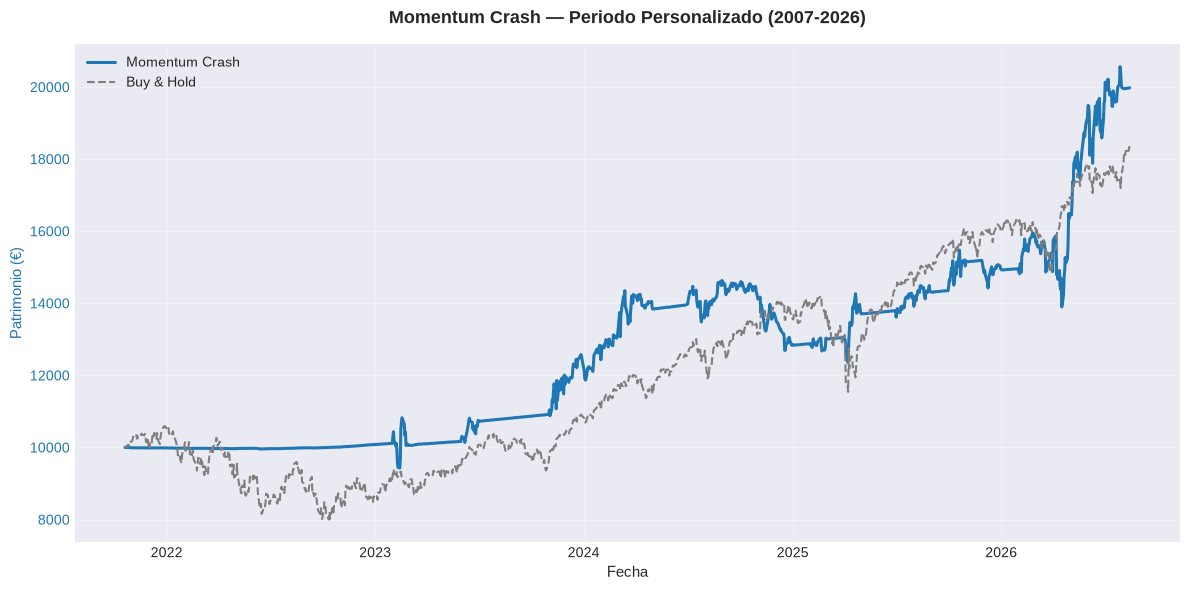


✅ Gráfico guardado en: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/figures/momentum_crash_periodo_personalizado_2007_2026.png


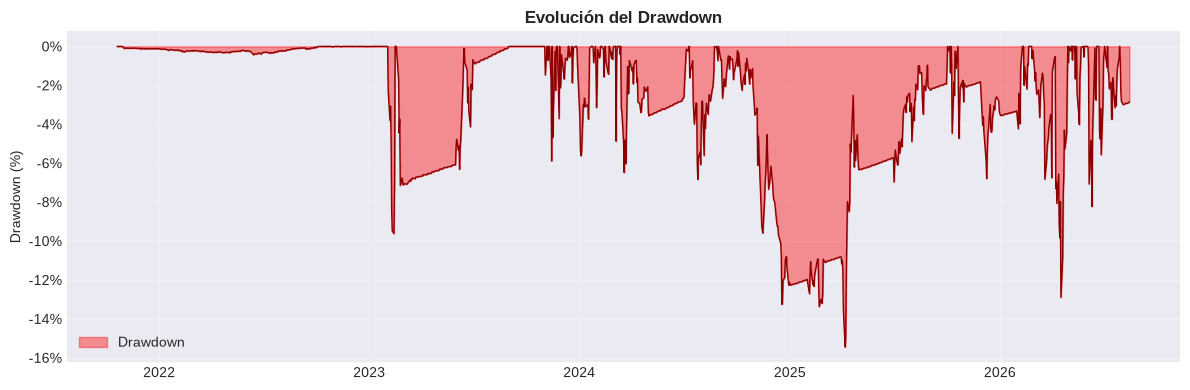

✅ Gráfico de drawdown guardado en: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/figures/momentum_crash_periodo_personalizado_2007_2026_drawdown.png


In [11]:
# %%
# ==============================================================================
# BLOQUE 8: VISUALIZACIÓN Y GUARDADO DE GRÁFICOS
# ==============================================================================
try:
    plt.style.use('seaborn-v0_8-darkgrid')
except:
    plt.style.use('seaborn-darkgrid')

fig, ax1 = plt.subplots(figsize=(12, 6))

color_estrategia = 'tab:blue'
color_bh = 'tab:gray'
ax1.set_xlabel('Fecha', fontsize=11)
ax1.set_ylabel('Patrimonio (€)', color=color_estrategia, fontsize=11)
ax1.plot(serie_pat.index, serie_pat,
         label='Momentum Crash', color=color_estrategia, lw=2.2)
ax1.plot(serie_bh.index, serie_bh,
         label='Buy & Hold', color=color_bh, lw=1.5, ls='--')
ax1.tick_params(axis='y', labelcolor=color_estrategia)
ax1.legend(loc='upper left', fontsize=10)
ax1.grid(True, alpha=0.3)

if serie_bmk is not None:
    ax2 = ax1.twinx()
    color_bench = 'tab:red'
    bench_norm = serie_bmk
    ax2.set_ylabel(f'Benchmark {BENCHMARK} (€)', color=color_bench, fontsize=11)
    ax2.plot(bench_norm.index, bench_norm, label=f'{BENCHMARK} (normalizado)',
             color=color_bench, lw=1.5, ls='-.')
    ax2.tick_params(axis='y', labelcolor=color_bench)
    ax2.legend(loc='upper right', fontsize=10)

titulo = f'Momentum Crash — {nombre_evento} ({fecha_ini[:4]}-{fecha_fin[:4]})'
plt.title(titulo, fontsize=13, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()

nombre_archivo = f"momentum_crash_{nombre_evento.replace(' ', '_')}_{fecha_ini[:4]}_{fecha_fin[:4]}".lower()
ruta_guardado = Path(gestor_proyecto.DIRS["OUTPUTS_FIGURES"]) / f"{nombre_archivo}.png"
fig.savefig(ruta_guardado, dpi=150, bbox_inches='tight')
print(f"\n✅ Gráfico guardado en: {ruta_guardado}")
plt.close()

fig2, ax = plt.subplots(figsize=(12, 4))
drawdown = (serie_pat / serie_pat.cummax()) - 1
ax.fill_between(drawdown.index, drawdown, 0, color='red', alpha=0.4, label='Drawdown')
ax.plot(drawdown.index, drawdown, color='darkred', lw=1)
ax.set_title('Evolución del Drawdown', fontsize=12, fontweight='bold')
ax.set_ylabel('Drawdown (%)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.grid(True, alpha=0.3)
ax.legend()
fig2.tight_layout()
plt.show()

ruta_dd = Path(gestor_proyecto.DIRS["OUTPUTS_FIGURES"]) / f"{nombre_archivo}_drawdown.png"
fig2.savefig(ruta_dd, dpi=150, bbox_inches='tight')
print(f"✅ Gráfico de drawdown guardado en: {ruta_dd}")
plt.close()

## BLOQUE 9: ANÁLISIS DE CORRELACIÓN FINAL


🔗 ANÁLISIS DE CORRELACIÓN DEL UNIVERSO

 TABLA DE CORRELACIONES (Retornos Diarios)
                             SPDR_S&P_500  Invesco_QQQ  Russell_2000_Small_Cap  MSCI_World  MSCI_Emerging_Markets  iShares_Russell_1000_Value  iShares_Russell_1000_Growth  SPDR_S&P_500_Value  SPDR_S&P_500_Growth  iShares_MSCI_USA_Min_Vol  iShares_MSCI_USA_Momentum  Technology_Select_Sector  Financial_Select_Sector  Energy_Select_Sector  Health_Care_Select_Sector  Industrial_Select_Sector  Consumer_Disc_Select_Sector  Materials_Select_Sector  Real_Estate_Select_Sector  Utilities_Select_Sector  Communication_Services  SPDR_Gold_Shares  United_States_Oil_Fund  VanEck_Semiconductor_ETF  ARK_Innovation_ETF  Bitcoin_Strategy_ETF  Short_Treasury_Bond_ETF
SPDR_S&P_500                         1.00         0.95                    0.85        0.98                   0.68                        0.90                         0.96                0.90                 0.96                      0.82                       

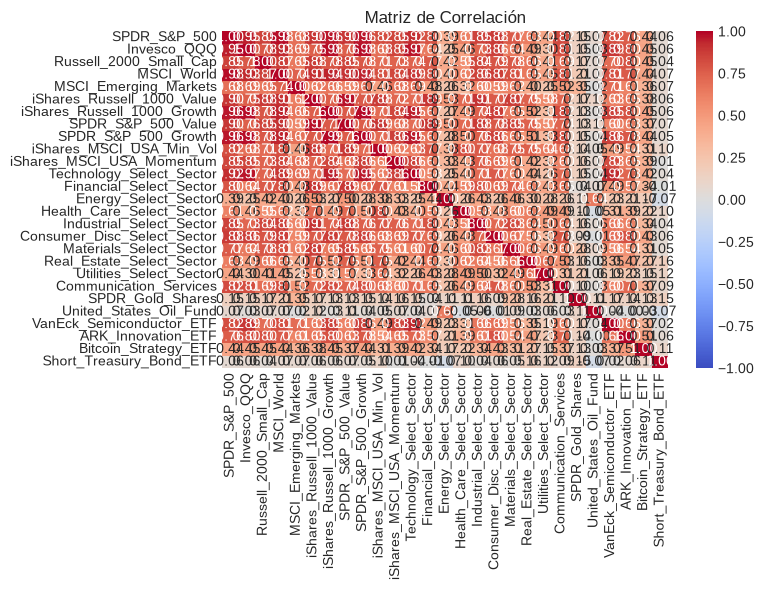


✅ Análisis de correlación completado.
   • Úsalo para identificar clusters de sectores altamente correlacionados.
   • Un universo ideal debe tener baja correlación interna
     para que la diversificación sea efectiva.


In [12]:
# %%
# ==============================================================================
# BLOQUE 9: ANÁLISIS DE CORRELACIÓN FINAL
# ==============================================================================
print("\n" + "="*70)
print("🔗 ANÁLISIS DE CORRELACIÓN DEL UNIVERSO")
print("="*70)

gestor.calcular_correlacion()

print("\n✅ Análisis de correlación completado.")
print("   • Úsalo para identificar clusters de sectores altamente correlacionados.")
print("   • Un universo ideal debe tener baja correlación interna")
print("     para que la diversificación sea efectiva.")

## BLOQUE 10: COMPARATIVA DE ESCENARIOS

,CAGR,Vol,Sharpe,MaxDD,Final €,Expo,Ops,Win-rate
Configuración del Bloque 0 (tal cual),15.53%,16.84%,0.71,-15.5%,"19,979",26%,74,64%
RSI más permisivo (≥ 60),15.83%,16.52%,0.74,-14.5%,"20,228",61%,175,59%
RSI más estricto (≥ 80),4.81%,5.54%,0.21,-5.7%,"12,528",1%,2,0%
Holding extendido (3 meses),17.56%,23.61%,0.59,-20.6%,"21,720",23%,23,91%
Holding muy corto (2 semanas ≈ 0.5 m),15.53%,16.84%,0.71,-15.5%,"19,979",26%,74,64%
Sin stop-loss,15.53%,16.84%,0.71,-15.5%,"19,979",26%,74,64%
Stop-loss más ajustado (-5%),15.53%,16.84%,0.71,-15.5%,"19,979",26%,74,64%
Stop-loss más holgado (-15%),15.53%,16.84%,0.71,-15.5%,"19,979",26%,74,64%
Menos concentración (top_n=3),14.58%,17.43%,0.63,-15.5%,"19,199",33%,57,58%
Más diversificación (top_n=8),15.05%,16.37%,0.70,-15.5%,"19,579",20%,92,65%


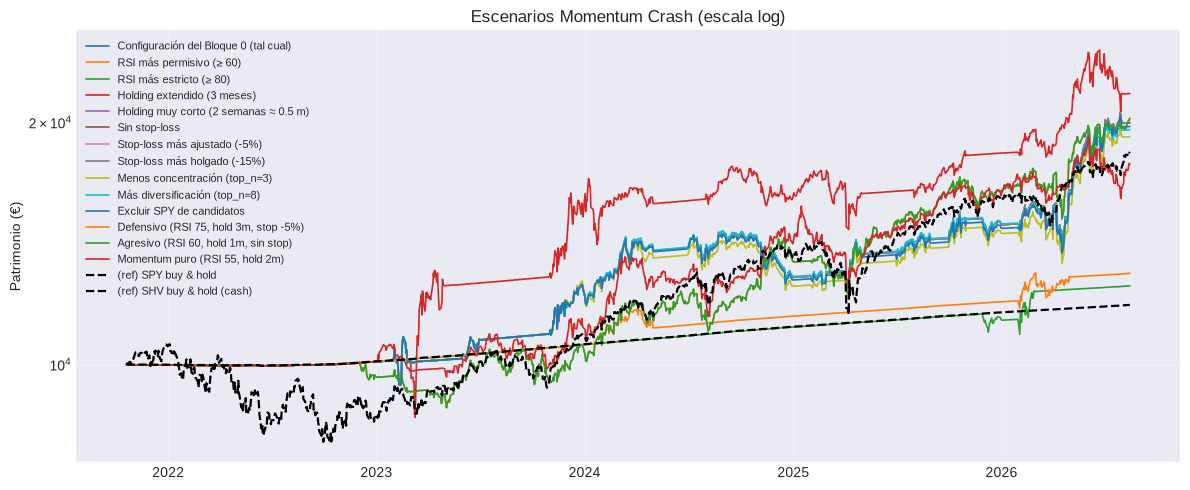

✅ Guardado en: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/figures/momentum_crash_escenarios.png

 Lectura de escenarios:
   • Compara cada variante con la configuración base (primera fila).
   • Busca zonas de parámetros estables, no puntos aislados.
   • Un escenario con mucha exposición ('Expo') y buen Sharpe es más robusto.
   • Si muchas variantes superan a la base, la estrategia es sensible a los parámetros.


In [13]:
# %%
# ==============================================================================
# BLOQUE 10: COMPARATIVA DE ESCENARIOS
# ==============================================================================
_R0 = dict()

ESCENARIOS = {
    'Configuración del Bloque 0 (tal cual)':     dict(),
    'RSI más permisivo (≥ 60)':                  {**_R0, 'umbral_rsi': 60.0},
    'RSI más estricto (≥ 80)':                   {**_R0, 'umbral_rsi': 80.0},
    'Holding extendido (3 meses)':               {**_R0, 'holding_meses': 3},
    'Holding muy corto (2 semanas ≈ 0.5 m)':     {**_R0, 'holding_meses': 0.5},
    'Sin stop-loss':                             {**_R0, 'stop_loss_pct': None},
    'Stop-loss más ajustado (-5%)':              {**_R0, 'stop_loss_pct': -0.05},
    'Stop-loss más holgado (-15%)':              {**_R0, 'stop_loss_pct': -0.15},
    'Menos concentración (top_n=3)':             {**_R0, 'top_n': 3},
    'Más diversificación (top_n=8)':             {**_R0, 'top_n': 8},
    'Excluir SPY de candidatos':                 {**_R0, 'excluir_spy': True},
    'Defensivo (RSI 75, hold 3m, stop -5%)':     {**_R0, 'umbral_rsi': 75.0, 
                                                   'holding_meses': 3, 
                                                   'stop_loss_pct': -0.05},
    'Agresivo (RSI 60, hold 1m, sin stop)':      {**_R0, 'umbral_rsi': 60.0, 
                                                   'holding_meses': 1, 
                                                   'stop_loss_pct': None},
    'Momentum puro (RSI 55, hold 2m)':           {**_R0, 'umbral_rsi': 55.0, 
                                                   'holding_meses': 2},
}

tabla_esc, series_esc = comparar_escenarios(
    MotorBacktestDinamico, gestor.precios_ajustados, gestor.rentabilidades_diarias,
    CFG_BASE, ESCENARIOS, cash_columna, columna_spy,
    coste=COSTE_TRANSACCION * 2, capital=CAPITAL_INICIAL, rf=RF_USADO)

fmt = {'CAGR': '{:.2%}', 'Vol': '{:.2%}', 'Sharpe': '{:.2f}', 'MaxDD': '{:.1%}',
       'Final €': '{:,.0f}', 'Expo': '{:.0%}', 'Ops': '{:.0f}', 'Win-rate': '{:.0%}'}
try:
    from IPython.display import display
    display(tabla_esc.style.format(fmt, na_rep='—'))
except Exception:
    print(tabla_esc.round(3).to_string())

fig, ax = plt.subplots(figsize=(12, 5))
for nombre, s_ in series_esc.items():
    ref = nombre.startswith('(ref)')
    ax.plot(s_.index, s_, label=nombre, lw=1.6 if ref else 1.2, ls='--' if ref else '-', color='black' if ref else None)
ax.set_yscale('log'); ax.set_title('Escenarios Momentum Crash (escala log)'); ax.set_ylabel('Patrimonio (€)')
ax.legend(fontsize=8, loc='upper left'); ax.grid(True, alpha=0.3)
fig.tight_layout(); plt.show()
ruta_esc = Path(gestor_proyecto.DIRS["OUTPUTS_FIGURES"]) / "momentum_crash_escenarios.png"
fig.savefig(ruta_esc, dpi=150, bbox_inches='tight'); plt.close()
print(f"✅ Guardado en: {ruta_esc}")

print("\n Lectura de escenarios:")
print("   • Compara cada variante con la configuración base (primera fila).")
print("   • Busca zonas de parámetros estables, no puntos aislados.")
print("   • Un escenario con mucha exposición ('Expo') y buen Sharpe es más robusto.")
print("   • Si muchas variantes superan a la base, la estrategia es sensible a los parámetros.")

## BLOQUE 11: BARRIDO DE PARÁMETROS (IS/OOS)

In [14]:
# %%
# ==============================================================================
# BLOQUE 11: BARRIDO DE PARÁMETROS — en muestra vs. fuera de muestra
# ==============================================================================
RUN_BARRIDO = True
FECHA_CORTE_OOS = '2024-01-01'

GRID = {
    'umbral_rsi': [60.0, 65.0, 70.0, 75.0, 80.0],
    'holding_meses': [0.5, 1, 2, 3],
    'top_n': [3, 5, 7],
    'stop_loss_pct': [None, -0.05, -0.08, -0.10, -0.15]
}

if RUN_BARRIDO:
    import itertools
    
    n_runs = int(np.prod([len(v) for v in GRID.values()]))
    print(f"⏳ Barrido de {n_runs} combinaciones (corte IS/OOS: {FECHA_CORTE_OOS})...")
    
    barrido = barrido_parametros(
        MotorBacktestDinamico, 
        gestor.precios_ajustados, 
        gestor.rentabilidades_diarias,
        CFG_BASE, 
        GRID, 
        cash_columna, 
        columna_spy,
        coste=COSTE_TRANSACCION * 2, 
        fecha_corte=FECHA_CORTE_OOS, 
        capital=CAPITAL_INICIAL, 
        rf=RF_USADO
    )
    
    if barrido.empty:
        print("⚠️ El barrido no devolvió resultados. Revisa que las combinaciones no fallen.")
    else:
        fmt_b = {c: '{:.2%}' for c in barrido.columns if c.startswith('CAGR')}
        fmt_b.update({c: '{:.1%}' for c in barrido.columns if c.startswith('MaxDD')})
        fmt_b.update({c: '{:.2f}' for c in barrido.columns if c.startswith('Sharpe')})
        fmt_b['Expo'] = '{:.0%}'
        fmt_b['Ops'] = '{:.0f}'
        
        top = barrido.sort_values('Sharpe_IS', ascending=False).head(10)
        print("\n🏆 Top 10 por Sharpe EN MUESTRA (mira cuánto se conserva fuera de muestra):")
        try:
            from IPython.display import display
            display(top.style.format(fmt_b, na_rep='—'))
        except Exception:
            print(top.round(3).to_string())
        
        rho = barrido['Sharpe_IS'].corr(barrido['Sharpe_OOS'], method='spearman')
        print(f"\n📐 Correlación de rangos (Spearman) Sharpe IS vs OOS: {rho:+.2f}")
        print("   ≈ 0  → el barrido está ajustando ruido: la 'mejor' combinación en muestra no predice la siguiente.")
        print("   > 0.4 → hay cierta estabilidad; busca zonas amplias de buenos resultados, no un punto aislado.")
        
        print("\n📊 Sharpe OOS medio por valor de parámetro:")
        for p in GRID:
            grupos = barrido.groupby(p)['Sharpe_OOS'].mean()
            print(f"   • {p}: " + " | ".join(f"{v}: {g:.2f}" for v, g in grupos.items()))
else:
    print("RUN_BARRIDO = False: barrido omitido.")

⏳ Barrido de 300 combinaciones (corte IS/OOS: 2024-01-01)...

🏆 Top 10 por Sharpe EN MUESTRA (mira cuánto se conserva fuera de muestra):


,umbral_rsi,holding_meses,top_n,stop_loss_pct,CAGR_IS,Sharpe_IS,MaxDD_IS,CAGR_OOS,Sharpe_OOS,MaxDD_OOS,Expo,Ops
168,70.000000,3.000000,3,-0.100000,21.34%,0.67,-20.6%,11.02%,0.34,-17.2%,29%,17
179,70.000000,3.000000,7,-0.150000,21.34%,0.67,-20.6%,17.24%,0.67,-17.2%,20%,27
176,70.000000,3.000000,7,-0.050000,21.34%,0.67,-20.6%,17.24%,0.67,-17.2%,20%,27
178,70.000000,3.000000,7,-0.100000,21.34%,0.67,-20.6%,17.24%,0.67,-17.2%,20%,27
172,70.000000,3.000000,5,-0.080000,21.34%,0.67,-20.6%,11.64%,0.39,-17.2%,23%,23
165,70.000000,3.000000,3,—,21.34%,0.67,-20.6%,11.02%,0.34,-17.2%,29%,17
166,70.000000,3.000000,3,-0.050000,21.34%,0.67,-20.6%,11.02%,0.34,-17.2%,29%,17
177,70.000000,3.000000,7,-0.080000,21.34%,0.67,-20.6%,17.24%,0.67,-17.2%,20%,27
174,70.000000,3.000000,5,-0.150000,21.34%,0.67,-20.6%,11.64%,0.39,-17.2%,23%,23
169,70.000000,3.000000,3,-0.150000,21.34%,0.67,-20.6%,11.02%,0.34,-17.2%,29%,17



📐 Correlación de rangos (Spearman) Sharpe IS vs OOS: +0.03
   ≈ 0  → el barrido está ajustando ruido: la 'mejor' combinación en muestra no predice la siguiente.
   > 0.4 → hay cierta estabilidad; busca zonas amplias de buenos resultados, no un punto aislado.

📊 Sharpe OOS medio por valor de parámetro:
   • umbral_rsi: 60.0: 1.15 | 65.0: 0.81 | 70.0: 0.68 | 75.0: 0.33 | 80.0: 1.03
   • holding_meses: 0.5: 0.79 | 1.0: 0.79 | 2.0: 1.07 | 3.0: 0.56
   • top_n: 3: 0.77 | 5: 0.80 | 7: 0.84
   • stop_loss_pct: -0.15: 0.80 | -0.1: 0.80 | -0.08: 0.80 | -0.05: 0.80


## BLOQUE 12: TESTS PLACEBO


⏳ Placebo 'seleccion': 200 simulaciones...
   ... 25/200 simulaciones (seleccion)
   ... 50/200 simulaciones (seleccion)
   ... 75/200 simulaciones (seleccion)
   ... 100/200 simulaciones (seleccion)
   ... 125/200 simulaciones (seleccion)
   ... 150/200 simulaciones (seleccion)
   ... 175/200 simulaciones (seleccion)
   ... 200/200 simulaciones (seleccion)

⏳ Placebo 'timing': 200 simulaciones...
   ... 25/200 simulaciones (timing)
   ... 50/200 simulaciones (timing)
   ... 75/200 simulaciones (timing)
   ... 100/200 simulaciones (timing)
   ... 125/200 simulaciones (timing)
   ... 150/200 simulaciones (timing)
   ... 175/200 simulaciones (timing)
   ... 200/200 simulaciones (timing)

⏳ Placebo 'total': 200 simulaciones...
   ... 25/200 simulaciones (total)
   ... 50/200 simulaciones (total)
   ... 75/200 simulaciones (total)
   ... 100/200 simulaciones (total)
   ... 125/200 simulaciones (total)
   ... 150/200 simulaciones (total)
   ... 175/200 simulaciones (total)
   ... 200/200 s

,Real,Placebo seleccion,Placebo timing,Placebo total
Ret_medio_op,0.0251,0.0195,0.0129,0.0105
CAGR,0.1553,0.0923,0.0908,0.0674
Sharpe,0.7066,0.4030,0.2664,0.1636
MaxDD,-0.1545,-0.1979,-0.3297,-0.3187
Expo,0.2576,0.2576,0.2576,0.2576



📊 p-valores unilaterales (proporción de placebos ≥ real; menor = más mérito):


,seleccion,timing,total
Ret_medio_op,0.154,0.065,0.040
CAGR,0.080,0.179,0.100
Sharpe,0.169,0.124,0.075
MaxDD,0.179,0.015,0.005


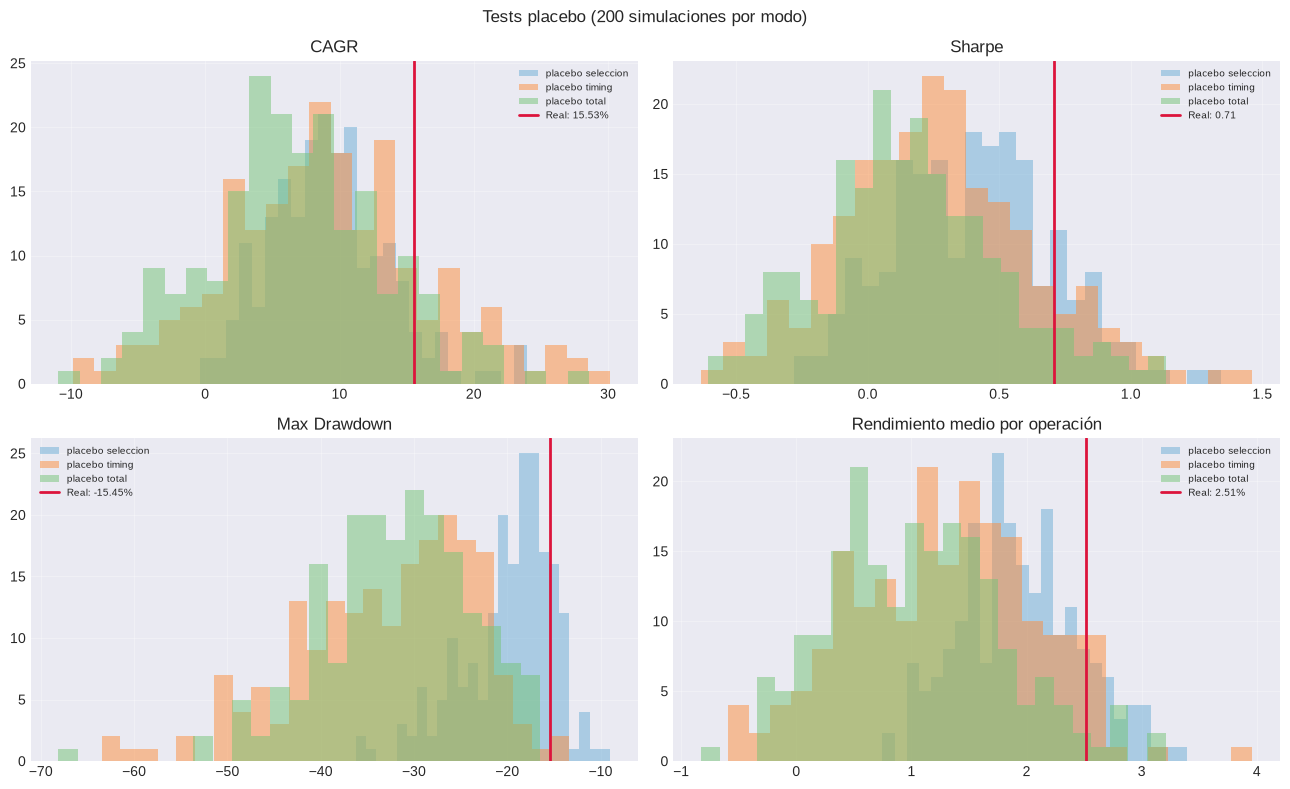

✅ Guardado en: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/figures/momentum_crash_placebo.png

🔎 Lectura (p-valores unilaterales; los estadísticos están muy correlacionados entre sí):

Selección (mismas fechas, ETF al azar)
   • Rendimiento medio por operación : p = 0.154 → indicio débil
   • CAGR                            : p = 0.080 → indicio débil
   • Sharpe                          : p = 0.169 → indicio débil
   • Max Drawdown                    : p = 0.179 → indicio débil

Timing (mismos ETFs, fechas al azar)
   • Rendimiento medio por operación : p = 0.065 → indicio débil
   • CAGR                            : p = 0.179 → indicio débil
   • Sharpe                          : p = 0.124 → indicio débil
   • Max Drawdown                    : p = 0.015 → por encima del azar

Total (fechas y ETFs al azar)
   • Rendimiento medio por operación : p = 0.040 → por encima del azar
   • CAGR                            : p = 0.100 → indicio débil
   • Sharpe                

In [15]:
# %%
# ==============================================================================
# BLOQUE 12: TESTS PLACEBO — selección, timing y total
# ==============================================================================
RUN_PLACEBO = True
MODOS_PLACEBO = ['seleccion', 'timing', 'total']
N_PLACEBO = 200
SEMILLA_PLACEBO = 42

if RUN_PLACEBO and MODOS_PLACEBO:
    resultados_placebo = {}
    
    for modo in MODOS_PLACEBO:
        print(f"\n⏳ Placebo '{modo}': {N_PLACEBO} simulaciones...")
        resultados_placebo[modo] = test_placebo(
            MotorBacktestDinamico, 
            gestor.precios_ajustados, 
            gestor.rentabilidades_diarias,
            CFG_BASE, 
            cash_columna, 
            columna_spy,
            coste=COSTE_TRANSACCION * 2, 
            n_sim=N_PLACEBO, 
            semilla=SEMILLA_PLACEBO, 
            capital=CAPITAL_INICIAL, 
            rf=RF_USADO, 
            modo=modo
        )
    
    real_ref = next(iter(resultados_placebo.values()))[2]
    metricas_tab = ['Ret_medio_op', 'CAGR', 'Sharpe', 'MaxDD']
    
    tabla_med = pd.DataFrame({'Real': [real_ref[k] for k in metricas_tab]}, index=metricas_tab)
    for m_, (res_, _, _) in resultados_placebo.items():
        tabla_med[f'Placebo {m_}'] = [res_.loc[k, 'placebo_media'] for k in metricas_tab]
    tabla_med.loc['Expo'] = [real_ref['Expo']] + [res_.loc['Expo', 'placebo_media'] for res_, _, _ in resultados_placebo.values()]
    
    tabla_p = pd.DataFrame({m_: res_['p_valor'].loc[metricas_tab] for m_, (res_, _, _) in resultados_placebo.items()})
    
    fmt_med = {c: '{:.4f}' for c in tabla_med.columns}
    print("\n📊 Valor real frente a la media de cada placebo:")
    try:
        from IPython.display import display
        display(tabla_med.style.format(fmt_med, na_rep='—'))
    except Exception:
        print(tabla_med.round(4).to_string())
    
    print("\n📊 p-valores unilaterales (proporción de placebos ≥ real; menor = más mérito):")
    try:
        display(tabla_p.style.format('{:.3f}'))
    except Exception:
        print(tabla_p.round(3).to_string())
    
    fig, axs = plt.subplots(2, 2, figsize=(13, 8))
    COLORES_MODO = {'seleccion': '#6baed6', 'timing': '#fd8d3c', 'total': '#74c476'}
    
    for ax, (col, titulo, pct) in zip(axs.ravel(), 
                                       [('CAGR', 'CAGR', True), 
                                        ('Sharpe', 'Sharpe', False),
                                        ('MaxDD', 'Max Drawdown', True),
                                        ('Ret_medio_op', 'Rendimiento medio por operación', True)]):
        k_ = 100 if pct else 1
        for m_, (_, sims_, _) in resultados_placebo.items():
            ax.hist(sims_[col].dropna() * k_, bins=25, alpha=0.5, color=COLORES_MODO[m_], label=f'placebo {m_}')
        v = real_ref[col] * k_
        ax.axvline(v, color='crimson', lw=2, label=f"Real: {v:.2f}{'%' if pct else ''}")
        ax.set_title(titulo)
        ax.legend(fontsize=7)
        ax.grid(alpha=0.3)
    
    fig.suptitle(f'Tests placebo ({N_PLACEBO} simulaciones por modo)', fontsize=12)
    fig.tight_layout()
    plt.show()
    
    ruta_pl = Path(gestor_proyecto.DIRS["OUTPUTS_FIGURES"]) / "momentum_crash_placebo.png"
    fig.savefig(ruta_pl, dpi=150, bbox_inches='tight')
    plt.close()
    print(f"✅ Guardado en: {ruta_pl}")
    
    def _veredicto(p):
        return "por encima del azar" if p <= 0.05 else "indicio débil" if p <= 0.20 else "no distinguible del azar"
    
    NOMBRES_MODO = {
        'seleccion': 'Selección (mismas fechas, ETF al azar)',
        'timing': 'Timing (mismos ETFs, fechas al azar)',
        'total': 'Total (fechas y ETFs al azar)'
    }
    
    print("\n🔎 Lectura (p-valores unilaterales; los estadísticos están muy correlacionados entre sí):")
    for m_ in resultados_placebo:
        print(f"\n{NOMBRES_MODO.get(m_, m_)}")
        for k_, nombre in [('Ret_medio_op', 'Rendimiento medio por operación'), 
                           ('CAGR', 'CAGR'),
                           ('Sharpe', 'Sharpe'), 
                           ('MaxDD', 'Max Drawdown')]:
            p_ = tabla_p.loc[k_, m_]
            print(f"   • {nombre:<32}: p = {p_:.3f} → {_veredicto(p_)}")
    
    print("""
   Cómo interpretarlos:
     • Selección: ¿elegir por RSI alto + momentum 12-1m bate a elegir al azar en las MISMAS fechas?
     • Timing: ¿entrar en esas fechas (sobrecompra) bate a entrar en fechas aleatorias con los MISMOS ETFs?
     • Total: ¿la estrategia completa bate a una con entradas totalmente aleatorias?
   Cautelas: es UNA configuración, UNA serie histórica y pocos episodios independientes.
   Un p-valor bajo no prueba nada definitivo; uno alto significa que no hay evidencia.
   Ausencia de evidencia ≠ evidencia de ausencia.""")
else:
    print("RUN_PLACEBO = False o MODOS_PLACEBO vacío: tests placebo omitidos.")

## BLOQUE 13: CONCLUSIONES ADAPTADAS

In [16]:
# %%
# ==============================================================================
# BLOQUE 13: CONCLUSIONES — generadas a partir de los resultados reales
# ==============================================================================

def _g(d, k, default=np.nan):
    try:
        return float(d.get(k, default))
    except Exception:
        return default

def _v(p):
    return "supera al azar" if p <= 0.05 else "indicio débil" if p <= 0.20 else "no se distingue del azar"

def _si(c): 
    return "SÍ" if c else "NO"

cagr_s, cagr_b = _g(metricas_reb, 'CAGR'), _g(metricas_bh, 'CAGR')
dd_s, dd_b = _g(metricas_reb, 'Max Drawdown'), _g(metricas_bh, 'Max Drawdown')
sh_s, sh_b = _g(metricas_reb, 'Sharpe'), _g(metricas_bh, 'Sharpe')
beta_s = _g(metricas_reb, 'Beta')
ir = _g(metricas_extras, 'Information Ratio') if 'metricas_extras' in dir() else np.nan
wr = _g(metricas_extras, 'Win-rate') if 'metricas_extras' in dir() else np.nan
n_ops = int(_g(metricas_extras, 'Operaciones Totales', 0)) if 'metricas_extras' in dir() else 0
expo_media = float(np.mean(estado_final.get('exposicion', [np.nan])))

try:
    cagr_shv = float(tabla_esc.loc['(ref) SHV buy & hold (cash)', 'CAGR'])
except Exception:
    cagr_shv = RF_USADO

tiene_placebo = 'resultados_placebo' in globals() and bool(resultados_placebo)
def _p(modo, k='Ret_medio_op'):
    try:
        return float(resultados_placebo[modo][0].loc[k, 'p_valor'])
    except Exception:
        return np.nan

# ---- Placebos ----
if tiene_placebo:
    _nom = {'seleccion': 'Selección (mismas fechas)', 
            'timing': 'Timing (mismos activos)', 
            'total': 'Todo al azar'}
    lin = []
    for _m, (_res, _sims, _real) in resultados_placebo.items():
        lin.append(f"  • {_nom[_m]:<26}: rend./operación real {_res.loc['Ret_medio_op','real']:.2%} vs placebo "
                   f"{_res.loc['Ret_medio_op','placebo_media']:.2%} (p = {_res.loc['Ret_medio_op','p_valor']:.3f}, "
                   f"{_v(_res.loc['Ret_medio_op','p_valor'])}) | CAGR p = {_res.loc['CAGR','p_valor']:.3f}")
    txt_placebo = "\n".join(lin)
else:
    txt_placebo = "  (tests placebo no ejecutados: RUN_PLACEBO = False)"

# ---- Lectura dinámica ----
L = []
bate_c, bate_s = cagr_s > cagr_b, sh_s > sh_b

if bate_c and bate_s:
    L.append(f"Como cartera SUPERA al buy & hold en CAGR ({cagr_s:.2%} vs {cagr_b:.2%}) y en Sharpe ({sh_s:.2f} vs {sh_b:.2f}).")
elif bate_c or bate_s:
    L.append(f"Como cartera el resultado es MIXTO frente al buy & hold: gana en {'CAGR' if bate_c else 'Sharpe'} "
             f"pero no en {'Sharpe' if bate_c else 'CAGR'} (CAGR {cagr_s:.2%} vs {cagr_b:.2%}; Sharpe {sh_s:.2f} vs {sh_b:.2f}).")
else:
    L.append(f"Como cartera NO supera al buy & hold ni en CAGR ({cagr_s:.2%} vs {cagr_b:.2%}) ni en Sharpe "
             f"({sh_s:.2f} vs {sh_b:.2f}; rf = {RF_USADO:.2%}).")

riesgo = (f"El drawdown máximo es {dd_s:.1%} frente a {dd_b:.1%} del buy & hold: "
          + ("lo reduce." if dd_s > dd_b else "no lo reduce."))
if dd_s <= -0.30:
    riesgo += " Es un drawdown profundo: revisa si coincide con una crisis."
L.append(riesgo)

if expo_media < 0.20:
    L.append(f"La exposición media es solo del {expo_media:.0%}: la estrategia pasa la mayor parte del tiempo en cash. "
             f"Su CAGR supera al de cash ({cagr_shv:.2%}) en {cagr_s - cagr_shv:+.2%} anual; es una cuña fina de renta variable "
             f"sobre efectivo, no una alternativa al buy & hold.")
else:
    L.append(f"La exposición media es del {expo_media:.0%}; el exceso de CAGR sobre cash ({cagr_shv:.2%}) es {cagr_s - cagr_shv:+.2%} anual.")

if tiene_placebo and not (np.isnan(_p('timing')) or np.isnan(_p('seleccion'))):
    p_tim, p_sel = _p('timing'), _p('seleccion')
    base_txt = (f"Frente a entradas aleatorias con la misma exposición: el MOMENTO de entrada {_v(p_tim)} (p = {p_tim:.3f}) "
                f"y la ELECCIÓN del activo {_v(p_sel)} (p = {p_sel:.3f}). ")
    if p_tim <= 0.05 and p_sel > 0.20:
        base_txt += "La ventaja viene del CUÁNDO (timing de sobrecompra), no del QUÉ."
    elif p_sel <= 0.05 and p_tim > 0.20:
        base_txt += "La ventaja viene del QUÉ (selección por momentum), no del CUÁNDO."
    elif p_tim > 0.20 and p_sel > 0.20:
        base_txt += "Ni el momento ni la elección se distinguen del azar."
    else:
        base_txt += "La evidencia es débil o mixta; no se puede atribuir con claridad a uno de los dos componentes."
    L.append(base_txt)

alpha_txt = f"Alpha de Jensen (rf = {RF_USADO:.2%}): {alpha_jensen:+.2%} con beta {beta_s:.2f}; Information Ratio {ir:+.2f}."
if abs(beta_s) < 0.15:
    alpha_txt += " Con beta casi nula el alpha es básicamente el exceso sobre efectivo, no una habilidad de mercado."
L.append(alpha_txt)

if 'rho' in globals():
    L.append(f"Barrido de parámetros: correlación IS/OOS (Spearman) = {rho:+.2f} → "
             + ("parámetros poco estables: no optimizar sobre esta muestra." if rho < 0.4 else "cierta estabilidad entre muestras."))

L.append("Cautelas: una sola configuración (elegida tras ver resultados), una sola serie histórica, "
         "pocos episodios independientes y estadísticos del placebo muy correlacionados entre sí.")
lectura = "\n".join(f"  {k}. {t}" for k, t in enumerate(L, 1))

# ---- Texto sugerido para el TFM ----
tfm = (f"Entre {serie_pat.index[0].year} y {serie_pat.index[-1].year}, la estrategia Momentum Crash obtuvo un CAGR del {cagr_s:.1%} "
       f"frente al {cagr_b:.1%} del buy & hold (Sharpe {sh_s:.2f} frente a {sh_b:.2f}), con un drawdown máximo de {dd_s:.1%} "
       f"(buy & hold: {dd_b:.1%}) y una exposición media del {expo_media:.0%}.")

if tiene_placebo and not (np.isnan(_p('timing')) or np.isnan(_p('seleccion'))):
    tfm += (f" Frente a entradas aleatorias con la misma exposición, el momento de entrada {_v(_p('timing'))} (p = {_p('timing'):.3f}) "
            f"y la selección del activo {_v(_p('seleccion'))} (p = {_p('seleccion'):.3f}).")

tfm += (" " + ("La estrategia no supera al buy & hold en rentabilidad ni en ratio de Sharpe." 
               if not (bate_c or bate_s) else
               "La estrategia supera al buy & hold en al menos una de las dos medidas."))

print("\n" + "=" * 70)
print(f"🎓 CONCLUSIONES: MOMENTUM CRASH (datos de esta ejecución)")
print("=" * 70)
print(f"""
Configuración: RSI ≥ {UMBRAL_RSI}, holding {HOLDING_MESES} mes(es), stop-loss {f'{STOP_LOSS_PCT:.0%}' if STOP_LOSS_PCT else 'None'}, top {TOP_N_GANADORES} ganadores

Periodo: {serie_pat.index[0].date()} → {serie_pat.index[-1].date()} | tasa libre de riesgo: {RF_USADO:.2%}

RESULTADO FRENTE AL BUY & HOLD
  • CAGR:          {cagr_s:7.2%}  vs  {cagr_b:7.2%}   → ¿bate al B&H? {_si(bate_c)}
  • Max Drawdown:  {dd_s:7.1%}  vs  {dd_b:7.1%}   → ¿reduce el drawdown? {_si(dd_s > dd_b)}
  • Sharpe:        {sh_s:7.2f}  vs  {sh_b:7.2f}   → ¿mejor ajustado al riesgo? {_si(bate_s)}
  • Beta vs {BENCHMARK}: {beta_s:.2f} | Alpha de Jensen: {alpha_jensen:+.2%} | Information Ratio: {ir:+.2f}
  • Operaciones: {n_ops} | Win-rate: {wr:.1%} | Exposición media: {expo_media:.0%}

SELECCIÓN Y TIMING FRENTE AL AZAR (Bloque 12)
{txt_placebo}

LECTURA
{lectura}

TEXTO SUGERIDO PARA EL TFM (ajústalo a tu redacción)
  {tfm}
""")
print("=" * 70)
print("✅ CAPÍTULO COMPLETADO")
print("=" * 70)


🎓 CONCLUSIONES: MOMENTUM CRASH (datos de esta ejecución)

Configuración: RSI ≥ 70.0, holding 1 mes(es), stop-loss -8%, top 5 ganadores

Periodo: 2021-10-20 → 2026-08-14 | tasa libre de riesgo: 3.63%

RESULTADO FRENTE AL BUY & HOLD
  • CAGR:           15.46%  vs   13.37%   → ¿bate al B&H? SÍ
  • Max Drawdown:   -15.5%  vs   -24.5%   → ¿reduce el drawdown? SÍ
  • Sharpe:           0.70  vs     0.56   → ¿mejor ajustado al riesgo? SÍ
  • Beta vs SPY: 0.00 | Alpha de Jensen: +nan% | Information Ratio: +nan
  • Operaciones: 0 | Win-rate: nan% | Exposición media: 26%

SELECCIÓN Y TIMING FRENTE AL AZAR (Bloque 12)
  • Selección (mismas fechas) : rend./operación real 2.51% vs placebo 1.95% (p = 0.154, indicio débil) | CAGR p = 0.080
  • Timing (mismos activos)   : rend./operación real 2.51% vs placebo 1.29% (p = 0.065, indicio débil) | CAGR p = 0.179
  • Todo al azar              : rend./operación real 2.51% vs placebo 1.05% (p = 0.040, supera al azar) | CAGR p = 0.100

LECTURA
  1. Como carte

In [17]:
# %%
# ==============================================================================
# BLOQUE 13: CONCLUSIONES — generadas a partir de los resultados reales
# ==============================================================================
def _g(d, k, default=np.nan):
    try:
        return float(d.get(k, default))
    except Exception:
        return default

def _v(p):
    return "supera al azar" if p <= 0.05 else "indicio débil" if p <= 0.20 else "no se distingue del azar"

def _si(c): 
    return "SÍ" if c else "NO"

cagr_s, cagr_b = _g(metricas_reb, 'CAGR'), _g(metricas_bh, 'CAGR')
dd_s, dd_b = _g(metricas_reb, 'Max Drawdown'), _g(metricas_bh, 'Max Drawdown')
sh_s, sh_b = _g(metricas_reb, 'Sharpe'), _g(metricas_bh, 'Sharpe')
beta_s = _g(metricas_reb, 'Beta')
ir = _g(metricas_extras, 'Information Ratio') if 'metricas_extras' in dir() else np.nan
wr = _g(metricas_extras, 'Win-rate') if 'metricas_extras' in dir() else np.nan
n_ops = int(_g(metricas_extras, 'Operaciones Totales', 0)) if 'metricas_extras' in dir() else 0
expo_media = float(np.mean(estado_final.get('exposicion', [np.nan])))

try:
    cagr_shv = float(tabla_esc.loc['(ref) SHV buy & hold (cash)', 'CAGR'])
except Exception:
    cagr_shv = RF_USADO

tiene_placebo = 'resultados_placebo' in globals() and bool(resultados_placebo)
def _p(modo, k='Ret_medio_op'):
    try:
        return float(resultados_placebo[modo][0].loc[k, 'p_valor'])
    except Exception:
        return np.nan

if tiene_placebo:
    _nom = {'seleccion': 'Selección (mismas fechas)', 
            'timing': 'Timing (mismos activos)', 
            'total': 'Todo al azar'}
    lin = []
    for _m, (_res, _sims, _real) in resultados_placebo.items():
        lin.append(f"  • {_nom[_m]:<26}: rend./operación real {_res.loc['Ret_medio_op','real']:.2%} vs placebo "
                   f"{_res.loc['Ret_medio_op','placebo_media']:.2%} (p = {_res.loc['Ret_medio_op','p_valor']:.3f}, "
                   f"{_v(_res.loc['Ret_medio_op','p_valor'])}) | CAGR p = {_res.loc['CAGR','p_valor']:.3f}")
    txt_placebo = "\n".join(lin)
else:
    txt_placebo = "  (tests placebo no ejecutados: RUN_PLACEBO = False)"

L = []
bate_c, bate_s = cagr_s > cagr_b, sh_s > sh_b

if bate_c and bate_s:
    L.append(f"Como cartera SUPERA al buy & hold en CAGR ({cagr_s:.2%} vs {cagr_b:.2%}) y en Sharpe ({sh_s:.2f} vs {sh_b:.2f}).")
elif bate_c or bate_s:
    L.append(f"Como cartera el resultado es MIXTO frente al buy & hold: gana en {'CAGR' if bate_c else 'Sharpe'} "
             f"pero no en {'Sharpe' if bate_c else 'CAGR'} (CAGR {cagr_s:.2%} vs {cagr_b:.2%}; Sharpe {sh_s:.2f} vs {sh_b:.2f}).")
else:
    L.append(f"Como cartera NO supera al buy & hold ni en CAGR ({cagr_s:.2%} vs {cagr_b:.2%}) ni en Sharpe "
             f"({sh_s:.2f} vs {sh_b:.2f}; rf = {RF_USADO:.2%}).")

riesgo = (f"El drawdown máximo es {dd_s:.1%} frente a {dd_b:.1%} del buy & hold: "
          + ("lo reduce." if dd_s > dd_b else "no lo reduce."))
if dd_s <= -0.30:
    riesgo += " Es un drawdown profundo: revisa si coincide con una crisis."
L.append(riesgo)

if expo_media < 0.20:
    L.append(f"La exposición media es solo del {expo_media:.0%}: la estrategia pasa la mayor parte del tiempo en cash. "
             f"Su CAGR supera al de cash ({cagr_shv:.2%}) en {cagr_s - cagr_shv:+.2%} anual; es una cuña fina de renta variable "
             f"sobre efectivo, no una alternativa al buy & hold.")
else:
    L.append(f"La exposición media es del {expo_media:.0%}; el exceso de CAGR sobre cash ({cagr_shv:.2%}) es {cagr_s - cagr_shv:+.2%} anual.")

if tiene_placebo and not (np.isnan(_p('timing')) or np.isnan(_p('seleccion'))):
    p_tim, p_sel = _p('timing'), _p('seleccion')
    base_txt = (f"Frente a entradas aleatorias con la misma exposición: el MOMENTO de entrada {_v(p_tim)} (p = {p_tim:.3f}) "
                f"y la ELECCIÓN del activo {_v(p_sel)} (p = {p_sel:.3f}). ")
    if p_tim <= 0.05 and p_sel > 0.20:
        base_txt += "La ventaja viene del CUÁNDO, no del QUÉ."
    elif p_sel <= 0.05 and p_tim > 0.20:
        base_txt += "La ventaja viene del QUÉ, no del CUÁNDO."
    elif p_tim > 0.20 and p_sel > 0.20:
        base_txt += "Ni el momento ni la elección se distinguen del azar."
    else:
        base_txt += "La evidencia es débil o mixta; no se puede atribuir con claridad a uno de los dos componentes."
    L.append(base_txt)

alpha_txt = f"Alpha de Jensen (rf = {RF_USADO:.2%}): {alpha_jensen:+.2%} con beta {beta_s:.2f}; Information Ratio {ir:+.2f}."
if abs(beta_s) < 0.15:
    alpha_txt += " Con beta casi nula el alpha es básicamente el exceso sobre efectivo, no una habilidad de mercado."
L.append(alpha_txt)

if 'rho' in globals():
    L.append(f"Barrido de parámetros: correlación IS/OOS (Spearman) = {rho:+.2f} → "
             + ("parámetros poco estables: no optimizar sobre esta muestra." if rho < 0.4 else "cierta estabilidad entre muestras."))

L.append("Cautelas: una sola configuración (elegida tras ver resultados), una sola serie histórica, "
         "pocos episodios independientes y estadísticos del placebo muy correlacionados entre sí.")
lectura = "\n".join(f"  {k}. {t}" for k, t in enumerate(L, 1))

tfm = (f"Entre {serie_pat.index[0].year} y {serie_pat.index[-1].year}, la estrategia Momentum Crash obtuvo un CAGR del {cagr_s:.1%} "
       f"frente al {cagr_b:.1%} del buy & hold (Sharpe {sh_s:.2f} frente a {sh_b:.2f}), con un drawdown máximo de {dd_s:.1%} "
       f"(buy & hold: {dd_b:.1%}) y una exposición media del {expo_media:.0%}.")

if tiene_placebo and not (np.isnan(_p('timing')) or np.isnan(_p('seleccion'))):
    tfm += (f" Frente a entradas aleatorias con la misma exposición, el momento de entrada {_v(_p('timing'))} (p = {_p('timing'):.3f}) "
            f"y la selección del activo {_v(_p('seleccion'))} (p = {_p('seleccion'):.3f}).")

tfm += (" " + ("La estrategia no supera al buy & hold en rentabilidad ni en ratio de Sharpe." 
               if not (bate_c or bate_s) else
               "La estrategia supera al buy & hold en al menos una de las dos medidas."))

print("\n" + "=" * 70)
print(f"🎓 CONCLUSIONES: MOMENTUM CRASH (datos de esta ejecución)")
print("=" * 70)
print(f"""
Configuración: RSI ≥ {UMBRAL_RSI}, holding {HOLDING_MESES} mes(es), stop-loss {f'{STOP_LOSS_PCT:.0%}' if STOP_LOSS_PCT else 'None'}, top {TOP_N_GANADORES} ganadoresPeriodo: {serie_pat.index[0].date()} → {serie_pat.index[-1].date()} | tasa libre de riesgo: {RF_USADO:.2%}

RESULTADO FRENTE AL BUY & HOLD
  • CAGR:          {cagr_s:7.2%}  vs  {cagr_b:7.2%}   → ¿bate al B&H? {_si(bate_c)}
  • Max Drawdown:  {dd_s:7.1%}  vs  {dd_b:7.1%}   → ¿reduce el drawdown? {_si(dd_s > dd_b)}
  • Sharpe:        {sh_s:7.2f}  vs  {sh_b:7.2f}   → ¿mejor ajustado al riesgo? {_si(bate_s)}
  • Beta vs {BENCHMARK}: {beta_s:.2f} | Alpha de Jensen: {alpha_jensen:+.2%} | Information Ratio: {ir:+.2f}
  • Operaciones: {n_ops} | Win-rate: {wr:.1%} | Exposición media: {expo_media:.0%}

SELECCIÓN Y TIMING FRENTE AL AZAR (Bloque 12)
{txt_placebo}

LECTURA
{lectura}

TEXTO SUGERIDO PARA EL TFM (ajústalo a tu redacción)
  {tfm}
""")
print("=" * 70)
print("✅ CAPÍTULO COMPLETADO")
print("=" * 70)


🎓 CONCLUSIONES: MOMENTUM CRASH (datos de esta ejecución)

Configuración: RSI ≥ 70.0, holding 1 mes(es), stop-loss -8%, top 5 ganadoresPeriodo: 2021-10-20 → 2026-08-14 | tasa libre de riesgo: 3.63%

RESULTADO FRENTE AL BUY & HOLD
  • CAGR:           15.46%  vs   13.37%   → ¿bate al B&H? SÍ
  • Max Drawdown:   -15.5%  vs   -24.5%   → ¿reduce el drawdown? SÍ
  • Sharpe:           0.70  vs     0.56   → ¿mejor ajustado al riesgo? SÍ
  • Beta vs SPY: 0.00 | Alpha de Jensen: +nan% | Information Ratio: +nan
  • Operaciones: 0 | Win-rate: nan% | Exposición media: 26%

SELECCIÓN Y TIMING FRENTE AL AZAR (Bloque 12)
  • Selección (mismas fechas) : rend./operación real 2.51% vs placebo 1.95% (p = 0.154, indicio débil) | CAGR p = 0.080
  • Timing (mismos activos)   : rend./operación real 2.51% vs placebo 1.29% (p = 0.065, indicio débil) | CAGR p = 0.179
  • Todo al azar              : rend./operación real 2.51% vs placebo 1.05% (p = 0.040, supera al azar) | CAGR p = 0.100

LECTURA
  1. Como cartera